<a href="https://colab.research.google.com/github/SaulJacov/AnalisisComobilidadCOVID-19/blob/main/notebooks/Analisis_Comorbilidades_COVID_Mexico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de comorbilidades en pacientes COVID-19 positivosen México
**Universo de estudio:** registros con `CLASIFICACION_FINAL IN (1, 2, 3)`

## Criterios metodológicos principales

- Una condición está presente únicamente cuando su código es `1`.
- El código `2` representa ausencia.
- Los códigos `97`, `98`, `99`, otros códigos y los valores nulos se mantienen como desconocidos/no especificados; **no se convierten en ausencia**.
- Una defunción se identifica cuando `FECHA_DEF` no es nula, no está vacía y es distinta de `9999-99-99`.
- `NUM_ENFERMEDADES` cuenta exclusivamente enfermedades con código `1`; no incluye tabaquismo.
- Debido a que una persona puede presentar varias condiciones, las gráficas circulares y las barras apiladas al 100% sobre composición representan **ocurrencias de condiciones**, no grupos mutuamente excluyentes de pacientes.
- Las expresiones de interpretación deben ser descriptivas: “se observó”, “mostró una mayor mortalidad” o “se encontró una asociación descriptiva”.

## 0. Índice

1. Preparación del entorno y configuración de rutas  
2. Definición de variables, catálogos y funciones  
3. Validaciones iniciales y construcción del universo positivo  
4. Descripción general del universo positivo  
5. Calidad y distribución de códigos  
6. Frecuencia de enfermedades y tabaquismo  
7. Mortalidad por enfermedad y tabaquismo  
8. Número de enfermedades registradas  
9. Combinaciones de enfermedades  
10. Análisis por sexo  
11. Análisis por grupos de edad  
12. Mortalidad y frecuencia por entidad de residencia  
13. Comparación específica de Nuevo León, CDMX, Jalisco, Colima y Estado de México  
14. Análisis específico del tabaquismo  
15. Resumen automático de hallazgos y archivos generados

## 1. Preparación del entorno

La primera ejecución instala las bibliotecas necesarias. Después se monta Google Drive. El Parquet no se modifica físicamente.

In [ ]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "polars>=1.20.0", "pyarrow>=15.0.0", "matplotlib>=3.8.0", "pandas>=2.0.0"
])

print("Dependencias instaladas correctamente.")

Dependencias instaladas correctamente.


In [ ]:
from pathlib import Path
import gc
import math
import warnings

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Entorno local detectado: no se montó Google Drive.")

print("Polars:", pl.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Polars: 1.35.2


### 1.1 Configuración de rutas


In [ ]:
# ===========================
# CONFIGURACIÓN DEL USUARIO
# ===========================
RUTA_PARQUET = Path(
    "/content/drive/MyDrive/Big Data/datos/220720COVID19MEXICO_limpio.parquet"
)

DIR_RESULTADOS = Path(
    "/content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades"
)
DIR_GRAFICAS = DIR_RESULTADOS / "graficas"

COLUMNAS_ESPERADAS = 40
REGISTROS_ESPERADOS = 17_311_019
POSITIVOS_ESPERADOS = 6_522_993
TOP_COMBINACIONES = 15

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
DIR_GRAFICAS.mkdir(parents=True, exist_ok=True)

print("Parquet:", RUTA_PARQUET)
print("Resultados:", DIR_RESULTADOS)

Parquet: /content/drive/MyDrive/Big Data/datos/220720COVID19MEXICO_limpio.parquet
Resultados: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades


## 2. Variables

In [ ]:
ENFERMEDADES = [
    "DIABETES",
    "EPOC",
    "ASMA",
    "HIPERTENSION",
    "CARDIOVASCULAR",
    "OBESIDAD",
    "RENAL_CRONICA",
    "OTRAS_COM",
    "INMUNOSUPRESION",
]

HABITOS = ["TABAQUISMO"]
VARIABLES_ANALISIS = ENFERMEDADES + HABITOS

ALIAS_COLUMNAS = {
    "OTRAS_COM": ["OTRAS_COM", "OTRA_COM"],
    "INMUNOSUPRESION": ["INMUNOSUPRESION", "INMUSUPR"],
}

GRUPOS_EDAD_ORDEN = [
    "0-17", "18-29", "30-39", "40-49",
    "50-59", "60-69", "70-79", "80 o más",
    "Edad anómala", "Edad desconocida",
]

CATEGORIAS_NUM_ENFERMEDADES = ["0", "1", "2", "3", "4", "5 o más"]

CATALOGO_ENTIDADES = {
    1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur",
    4: "Campeche", 5: "Coahuila de Zaragoza", 6: "Colima",
    7: "Chiapas", 8: "Chihuahua", 9: "Ciudad de México",
    10: "Durango", 11: "Guanajuato", 12: "Guerrero", 13: "Hidalgo",
    14: "Jalisco", 15: "Estado de México", 16: "Michoacán de Ocampo",
    17: "Morelos", 18: "Nayarit", 19: "Nuevo León", 20: "Oaxaca",
    21: "Puebla", 22: "Querétaro", 23: "Quintana Roo",
    24: "San Luis Potosí", 25: "Sinaloa", 26: "Sonora",
    27: "Tabasco", 28: "Tamaulipas", 29: "Tlaxcala",
    30: "Veracruz de Ignacio de la Llave", 31: "Yucatán", 32: "Zacatecas",
    36: "Estados Unidos Mexicanos", 97: "No aplica", 98: "Se ignora",
    99: "No especificado",
}

ESTADOS_SELECCIONADOS = {
    19: "Nuevo León",
    9: "Ciudad de México",
    14: "Jalisco",
    6: "Colima",
    15: "Estado de México",
}

assert "NEUMONIA" not in VARIABLES_ANALISIS
assert len(VARIABLES_ANALISIS) == len(set(VARIABLES_ANALISIS))
print("Clasificación validada:", len(ENFERMEDADES), "enfermedades y", len(HABITOS), "hábito.")

Clasificación validada: 9 enfermedades y 1 hábito.


In [ ]:
def collect_streaming(lf: pl.LazyFrame) -> pl.DataFrame:
    """Materializa un LazyFrame usando el motor streaming cuando sea compatible."""
    try:
        return lf.collect(engine="streaming")
    except Exception as exc:
        if "stream" not in str(exc).lower() and "engine" not in str(exc).lower():
            raise
        return lf.collect()


def porcentaje(numerador, denominador):
    if denominador in (0, None) or pd.isna(denominador):
        return np.nan
    return float(numerador) / float(denominador) * 100.0


def guardar_csv(df: pl.DataFrame, nombre: str):
    ruta = DIR_RESULTADOS / nombre
    df.write_csv(ruta)
    print("Guardado:", ruta)


def guardar_figura(fig, nombre: str, dpi: int = 180):
    ruta = DIR_GRAFICAS / nombre
    fig.savefig(ruta, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Guardada:", ruta)


def nombre_entidad(codigo):
    if codigo is None or (isinstance(codigo, float) and np.isnan(codigo)):
        return "Código no disponible"
    codigo = int(codigo)
    return CATALOGO_ENTIDADES.get(codigo, f"Código no catalogado ({codigo})")


def resolver_alias(nombre_canonico: str, columnas: list[str]) -> str:
    candidatos = ALIAS_COLUMNAS.get(nombre_canonico, [nombre_canonico])
    encontrados = [c for c in candidatos if c in columnas]
    if not encontrados:
        raise KeyError(
            f"No se encontró la columna para {nombre_canonico}. "
            f"Se buscaron: {candidatos}"
        )
    return encontrados[0]


def tabla_variables_por_grupo(lf: pl.LazyFrame, grupo: str) -> pl.DataFrame:
    """Agrega las 10 variables por una dimensión sin expandir el dataset a formato largo."""
    expresiones = [
        pl.len().alias("__TOTAL_GRUPO"),
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("__DEFUNCIONES_GRUPO"),
    ]
    for variable in VARIABLES_ANALISIS:
        presente = pl.col(variable) == 1
        expresiones.extend([
            presente.cast(pl.Int64).sum().alias(f"{variable}__PACIENTES"),
            (presente & pl.col("FALLECIDO")).cast(pl.Int64).sum().alias(f"{variable}__DEFUNCIONES"),
        ])

    ancho = collect_streaming(lf.group_by(grupo).agg(expresiones))
    filas = []
    for fila in ancho.iter_rows(named=True):
        total_grupo = int(fila["__TOTAL_GRUPO"])
        for variable in VARIABLES_ANALISIS:
            pacientes = int(fila[f"{variable}__PACIENTES"] or 0)
            defunciones = int(fila[f"{variable}__DEFUNCIONES"] or 0)
            filas.append({
                grupo: fila[grupo],
                "TIPO_VARIABLE": (
                    "Enfermedad o condición clínica"
                    if variable in ENFERMEDADES
                    else "Hábito o factor de riesgo"
                ),
                "VARIABLE": variable,
                "TOTAL_GRUPO": total_grupo,
                "PACIENTES_CON_VARIABLE": pacientes,
                "FRECUENCIA_PORCENTAJE": porcentaje(pacientes, total_grupo),
                "DEFUNCIONES_CON_VARIABLE": defunciones,
                "MORTALIDAD_PORCENTAJE": porcentaje(defunciones, pacientes),
            })
    return pl.DataFrame(filas)


def ordenar_por_lista(pdf: pd.DataFrame, columna: str, orden: list[str]) -> pd.DataFrame:
    salida = pdf.copy()
    salida[columna] = pd.Categorical(salida[columna], categories=orden, ordered=True)
    return salida.sort_values(columna)

## 3. Validaciones iniciales y universo positivo


In [ ]:
if not RUTA_PARQUET.exists():
    raise FileNotFoundError(
        f"No se encontró el Parquet en: {RUTA_PARQUET}. "
        "Corrige RUTA_PARQUET y vuelve a ejecutar."
    )

lf_archivo = pl.scan_parquet(str(RUTA_PARQUET))
esquema = lf_archivo.collect_schema()
columnas_originales = esquema.names()

print("Columnas detectadas:", len(columnas_originales))
print(columnas_originales)

if len(columnas_originales) != COLUMNAS_ESPERADAS:
    raise AssertionError(
        f"Se esperaban {COLUMNAS_ESPERADAS} columnas y se detectaron {len(columnas_originales)}."
    )

mapeo_columnas = {
    variable: resolver_alias(variable, columnas_originales)
    for variable in VARIABLES_ANALISIS
}

columnas_base_requeridas = [
    "CLASIFICACION_FINAL", "FECHA_DEF", "SEXO", "EDAD", "ENTIDAD_RES"
]
faltantes_base = [c for c in columnas_base_requeridas if c not in columnas_originales]
if faltantes_base:
    raise KeyError(f"Faltan columnas esenciales: {faltantes_base}")

print("Aliases resueltos:")
for canonica, original in mapeo_columnas.items():
    print(f"  {canonica:20s} <- {original}")

Columnas detectadas: 40
['FECHA_ACTUALIZACION', 'ID_REGISTRO', 'ORIGEN', 'SECTOR', 'ENTIDAD_UM', 'SEXO', 'ENTIDAD_NAC', 'ENTIDAD_RES', 'MUNICIPIO_RES', 'TIPO_PACIENTE', 'FECHA_INGRESO', 'FECHA_SINTOMAS', 'FECHA_DEF', 'INTUBADO', 'NEUMONIA', 'EDAD', 'NACIONALIDAD', 'EMBARAZO', 'HABLA_LENGUA_INDIG', 'INDIGENA', 'DIABETES', 'EPOC', 'ASMA', 'INMUSUPR', 'HIPERTENSION', 'OTRA_COM', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO', 'OTRO_CASO', 'TOMA_MUESTRA_LAB', 'RESULTADO_LAB', 'TOMA_MUESTRA_ANTIGENO', 'RESULTADO_ANTIGENO', 'CLASIFICACION_FINAL', 'MIGRANTE', 'PAIS_NACIONALIDAD', 'PAIS_ORIGEN', 'UCI']
Aliases resueltos:
  DIABETES             <- DIABETES
  EPOC                 <- EPOC
  ASMA                 <- ASMA
  HIPERTENSION         <- HIPERTENSION
  CARDIOVASCULAR       <- CARDIOVASCULAR
  OBESIDAD             <- OBESIDAD
  RENAL_CRONICA        <- RENAL_CRONICA
  OTRAS_COM            <- OTRA_COM
  INMUNOSUPRESION      <- INMUSUPR
  TABAQUISMO           <- TABAQUISMO


In [ ]:
# Proyección: solo se leen las columnas necesarias para el análisis.
expresiones_proyeccion = [
    pl.col("CLASIFICACION_FINAL").cast(pl.Int16, strict=False).alias("CLASIFICACION_FINAL"),
    pl.col("FECHA_DEF").cast(pl.String, strict=False).alias("FECHA_DEF"),
    pl.col("SEXO").cast(pl.Int16, strict=False).alias("SEXO_COD"),
    pl.col("EDAD").cast(pl.Int16, strict=False).alias("EDAD_NUM"),
    pl.col("ENTIDAD_RES").cast(pl.Int16, strict=False).alias("ENTIDAD_RES_COD"),
]
expresiones_proyeccion.extend([
    pl.col(original).cast(pl.Int16, strict=False).alias(canonica)
    for canonica, original in mapeo_columnas.items()
])

lf_proyectado = lf_archivo.select(expresiones_proyeccion)

fecha_def_txt = pl.col("FECHA_DEF").str.strip_chars()
fallecido_expr = (
    fecha_def_txt.is_not_null()
    & (fecha_def_txt != "")
    & (fecha_def_txt != "9999-99-99")
)

edad = pl.col("EDAD_NUM")
grupo_edad_expr = (
    pl.when(edad.is_null()).then(pl.lit("Edad desconocida"))
    .when((edad < 0) | (edad > 120)).then(pl.lit("Edad anómala"))
    .when(edad <= 17).then(pl.lit("0-17"))
    .when(edad <= 29).then(pl.lit("18-29"))
    .when(edad <= 39).then(pl.lit("30-39"))
    .when(edad <= 49).then(pl.lit("40-49"))
    .when(edad <= 59).then(pl.lit("50-59"))
    .when(edad <= 69).then(pl.lit("60-69"))
    .when(edad <= 79).then(pl.lit("70-79"))
    .otherwise(pl.lit("80 o más"))
)

sexo = pl.col("SEXO_COD")
sexo_expr = (
    pl.when(sexo == 1).then(pl.lit("Mujer"))
    .when(sexo == 2).then(pl.lit("Hombre"))
    .when(sexo == 99).then(pl.lit("No especificado"))
    .when(sexo.is_null()).then(pl.lit("Código nulo"))
    .otherwise(pl.concat_str([pl.lit("Código "), sexo.cast(pl.String)]))
)

num_enfermedades_expr = pl.sum_horizontal([
    (pl.col(variable) == 1).cast(pl.Int8)
    for variable in ENFERMEDADES
]).alias("NUM_ENFERMEDADES")

lf_positivos = (
    lf_proyectado
    .filter(pl.col("CLASIFICACION_FINAL").is_in([1, 2, 3]))
    .with_columns([
        fallecido_expr.alias("FALLECIDO"),
        grupo_edad_expr.alias("GRUPO_EDAD"),
        sexo_expr.alias("SEXO_CATEGORIA"),
        num_enfermedades_expr,
    ])
    .with_columns([
        pl.when(pl.col("NUM_ENFERMEDADES") >= 5).then(pl.lit("5 o más"))
        .otherwise(pl.col("NUM_ENFERMEDADES").cast(pl.String))
        .alias("CATEGORIA_NUM_ENFERMEDADES"),
        pl.when(pl.col("TABAQUISMO") == 1).then(pl.lit("Presente"))
        .when(pl.col("TABAQUISMO") == 2).then(pl.lit("Ausente"))
        .otherwise(pl.lit("Desconocido/no especificado"))
        .alias("TABAQUISMO_ESTADO"),
    ])
)

print("LazyFrame positivo construido sin modificar el Parquet.")

LazyFrame positivo construido sin modificar el Parquet.


In [ ]:
conteos_validacion = collect_streaming(
    lf_archivo.select(pl.len().alias("TOTAL_REGISTROS"))
).row(0, named=True)

total_registros = int(conteos_validacion["TOTAL_REGISTROS"])
total_positivos = int(
    collect_streaming(lf_positivos.select(pl.len().alias("TOTAL_POSITIVOS")))
    .item()
)

if total_registros != REGISTROS_ESPERADOS:
    raise AssertionError(
        f"Registros: se esperaban {REGISTROS_ESPERADOS:,} y se obtuvieron {total_registros:,}."
    )
if total_positivos != POSITIVOS_ESPERADOS:
    raise AssertionError(
        f"Positivos: se esperaban {POSITIVOS_ESPERADOS:,} y se obtuvieron {total_positivos:,}."
    )

resumen_defunciones = collect_streaming(
    lf_positivos.select([
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("FALLECIDOS"),
        (~pl.col("FALLECIDO")).cast(pl.Int64).sum().alias("NO_FALLECIDOS"),
    ])
).row(0, named=True)

total_fallecidos = int(resumen_defunciones["FALLECIDOS"])
total_no_fallecidos = int(resumen_defunciones["NO_FALLECIDOS"])

print(f"✓ Columnas: {len(columnas_originales):,}")
print(f"✓ Registros limpios: {total_registros:,}")
print(f"✓ Positivos: {total_positivos:,}")
print(f"✓ Fallecidos positivos: {total_fallecidos:,}")
print(f"✓ No fallecidos positivos: {total_no_fallecidos:,}")
print(f"✓ Mortalidad general: {porcentaje(total_fallecidos, total_positivos):.2f}%")

✓ Columnas: 40
✓ Registros limpios: 17,311,019
✓ Positivos: 6,522,993
✓ Fallecidos positivos: 326,765
✓ No fallecidos positivos: 6,196,228
✓ Mortalidad general: 5.01%


### 3.1 Códigos observados y edades anómalas

Se documentan los códigos de `SEXO`, los valores anómalos de edad y la distribución de los códigos de las variables. Los valores desconocidos no se interpretan como ausencia.

In [ ]:
codigos_sexo = collect_streaming(
    lf_positivos.group_by(["SEXO_COD", "SEXO_CATEGORIA"])
    .agg(pl.len().alias("PACIENTES"))
    .sort("SEXO_COD")
)
print("Códigos de SEXO observados:")
display(codigos_sexo.to_pandas())

edades_anomalas = collect_streaming(
    lf_positivos.filter(
        pl.col("EDAD_NUM").is_null()
        | (pl.col("EDAD_NUM") < 0)
        | (pl.col("EDAD_NUM") > 120)
    )
    .group_by("EDAD_NUM")
    .agg(pl.len().alias("REGISTROS"))
    .sort("EDAD_NUM")
)

print("Valores de edad nulos o fuera del intervalo 0-120:")
display(edades_anomalas.to_pandas())

Códigos de SEXO observados:


,SEXO_COD,SEXO_CATEGORIA,PACIENTES
0,1,Mujer,3444987
1,2,Hombre,3078006


Valores de edad nulos o fuera del intervalo 0-120:


,EDAD_NUM,REGISTROS
0,121,31
1,122,12
2,135,1
3,147,1


In [ ]:
# Una sola agregación obtiene la calidad de las 10 variables.
expresiones_calidad = []
for variable in VARIABLES_ANALISIS:
    col = pl.col(variable)
    expresiones_calidad.extend([
        (col == 1).cast(pl.Int64).sum().alias(f"{variable}__1"),
        (col == 2).cast(pl.Int64).sum().alias(f"{variable}__2"),
        (col == 97).cast(pl.Int64).sum().alias(f"{variable}__97"),
        (col == 98).cast(pl.Int64).sum().alias(f"{variable}__98"),
        (col == 99).cast(pl.Int64).sum().alias(f"{variable}__99"),
        col.is_null().cast(pl.Int64).sum().alias(f"{variable}__NULOS"),
        (
            col.is_not_null() & ~col.is_in([1, 2, 97, 98, 99])
        ).cast(pl.Int64).sum().alias(f"{variable}__OTROS"),
    ])

calidad_ancha = collect_streaming(lf_positivos.select(expresiones_calidad)).row(0, named=True)
filas_calidad = []
for variable in VARIABLES_ANALISIS:
    c1 = int(calidad_ancha[f"{variable}__1"] or 0)
    c2 = int(calidad_ancha[f"{variable}__2"] or 0)
    c97 = int(calidad_ancha[f"{variable}__97"] or 0)
    c98 = int(calidad_ancha[f"{variable}__98"] or 0)
    c99 = int(calidad_ancha[f"{variable}__99"] or 0)
    nulos = int(calidad_ancha[f"{variable}__NULOS"] or 0)
    otros = int(calidad_ancha[f"{variable}__OTROS"] or 0)
    desconocidos = c97 + c98 + c99 + nulos + otros
    filas_calidad.append({
        "TIPO_VARIABLE": "Enfermedad o condición clínica" if variable in ENFERMEDADES else "Hábito o factor de riesgo",
        "VARIABLE": variable,
        "CODIGO_1_PRESENTE": c1,
        "CODIGO_2_AUSENTE": c2,
        "CODIGO_97": c97,
        "CODIGO_98": c98,
        "CODIGO_99": c99,
        "NULOS": nulos,
        "OTROS_CODIGOS": otros,
        "TOTAL_DESCONOCIDO_NO_ESPECIFICADO": desconocidos,
        "PORCENTAJE_PRESENCIA": porcentaje(c1, total_positivos),
        "PORCENTAJE_AUSENCIA": porcentaje(c2, total_positivos),
        "PORCENTAJE_DESCONOCIDO": porcentaje(desconocidos, total_positivos),
    })

calidad_variables = pl.DataFrame(filas_calidad).sort("PORCENTAJE_PRESENCIA", descending=True)
guardar_csv(calidad_variables, "calidad_variables.csv")
display(calidad_variables.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/calidad_variables.csv


,TIPO_VARIABLE,VARIABLE,CODIGO_1_PRESENTE,CODIGO_2_AUSENTE,CODIGO_97,CODIGO_98,CODIGO_99,NULOS,OTROS_CODIGOS,TOTAL_DESCONOCIDO_NO_ESPECIFICADO,PORCENTAJE_PRESENCIA,PORCENTAJE_AUSENCIA,PORCENTAJE_DESCONOCIDO
0,Enfermedad o condición clínica,HIPERTENSION,790052,5714793,0,18148,0,0,0,18148,12.111802,87.609982,0.278216
1,Enfermedad o condición clínica,OBESIDAD,649589,5856384,0,17020,0,0,0,17020,9.958450,89.780627,0.260923
2,Enfermedad o condición clínica,DIABETES,587403,5916559,0,19031,0,0,0,19031,9.005115,90.703133,0.291753
3,Hábito o factor de riesgo,TABAQUISMO,368343,6136122,0,18528,0,0,0,18528,5.646840,94.069118,0.284041
4,Enfermedad o condición clínica,ASMA,123522,6381510,0,17961,0,0,0,17961,1.893640,97.831011,0.275349
5,Enfermedad o condición clínica,OTRAS_COM,97419,6375958,0,49616,0,0,0,49616,1.493471,97.745897,0.760632
6,Enfermedad o condición clínica,CARDIOVASCULAR,66337,6438481,0,18175,0,0,0,18175,1.016972,98.704398,0.278630
7,Enfermedad o condición clínica,RENAL_CRONICA,64072,6440859,0,18062,0,0,0,18062,0.982248,98.740854,0.276897
8,Enfermedad o condición clínica,EPOC,45858,6459000,0,18135,0,0,0,18135,0.703021,99.018963,0.278017
9,Enfermedad o condición clínica,INMUNOSUPRESION,37240,6467579,0,18174,0,0,0,18174,0.570904,99.150482,0.278614


## 4. Descripción general del universo positivo

Esta sección responde cuántos pacientes positivos, fallecidos y no fallecidos existen, y cómo se distribuyen por sexo, edad y entidad de residencia.

In [ ]:
resumen_general = pl.DataFrame({
    "METRICA": [
        "Registros limpios",
        "Pacientes COVID positivos",
        "Fallecidos entre positivos",
        "No fallecidos entre positivos",
        "Mortalidad general (%)",
    ],
    "VALOR": [
        float(total_registros),
        float(total_positivos),
        float(total_fallecidos),
        float(total_no_fallecidos),
        porcentaje(total_fallecidos, total_positivos),
    ],
})
guardar_csv(resumen_general, "resumen_general.csv")
display(resumen_general.to_pandas())

# Distribución por sexo
distribucion_sexo = collect_streaming(
    lf_positivos.group_by(["SEXO_COD", "SEXO_CATEGORIA"])
    .agg([
        pl.len().alias("PACIENTES"),
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
    ])
).with_columns([
    (pl.col("PACIENTES") / total_positivos * 100).alias("PORCENTAJE_POSITIVOS"),
    (pl.col("DEFUNCIONES") / pl.col("PACIENTES") * 100).alias("MORTALIDAD_PORCENTAJE"),
]).sort("PACIENTES", descending=True)

guardar_csv(distribucion_sexo, "distribucion_sexo.csv")
display(distribucion_sexo.to_pandas())

# Distribución por grupos de edad
distribucion_grupo_edad = collect_streaming(
    lf_positivos.group_by("GRUPO_EDAD")
    .agg([
        pl.len().alias("PACIENTES"),
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
    ])
).with_columns([
    (pl.col("PACIENTES") / total_positivos * 100).alias("PORCENTAJE_POSITIVOS"),
    (pl.col("DEFUNCIONES") / pl.col("PACIENTES") * 100).alias("MORTALIDAD_PORCENTAJE"),
])

pdf_edad = ordenar_por_lista(distribucion_grupo_edad.to_pandas(), "GRUPO_EDAD", GRUPOS_EDAD_ORDEN)
distribucion_grupo_edad = pl.from_pandas(pdf_edad)
guardar_csv(distribucion_grupo_edad, "distribucion_grupo_edad.csv")
display(pdf_edad)

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/resumen_general.csv


,METRICA,VALOR
0,Registros limpios,1.731102e+07
1,Pacientes COVID positivos,6.522993e+06
2,Fallecidos entre positivos,3.267650e+05
3,No fallecidos entre positivos,6.196228e+06
4,Mortalidad general (%),5.009434e+00


Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/distribucion_sexo.csv


,SEXO_COD,SEXO_CATEGORIA,PACIENTES,DEFUNCIONES,PORCENTAJE_POSITIVOS,MORTALIDAD_PORCENTAJE
0,1,Mujer,3444987,125623,52.81298,3.646545
1,2,Hombre,3078006,201142,47.18702,6.534815


Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/distribucion_grupo_edad.csv


,GRUPO_EDAD,PACIENTES,DEFUNCIONES,PORCENTAJE_POSITIVOS,MORTALIDAD_PORCENTAJE
7,0-17,423888,1307,6.498367,0.308336
1,18-29,1530609,5076,23.464827,0.331633
6,30-39,1499120,15140,22.982088,1.009926
5,40-49,1276340,35865,19.566785,2.809988
4,50-59,931670,64917,14.282861,6.967810
0,60-69,499530,86742,7.657988,17.364723
3,70-79,245927,72843,3.770156,29.619765
2,80 o más,115864,44873,1.776240,38.729027
8,Edad anómala,45,2,0.000690,4.444444


In [ ]:
# Casos y defunciones por entidad de residencia
mortalidad_por_estado = collect_streaming(
    lf_positivos.group_by("ENTIDAD_RES_COD")
    .agg([
        pl.len().alias("CASOS_POSITIVOS"),
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
    ])
).with_columns(
    (pl.col("DEFUNCIONES") / pl.col("CASOS_POSITIVOS") * 100)
    .alias("MORTALIDAD_PORCENTAJE")
)

mortalidad_por_estado = mortalidad_por_estado.with_columns(
    pl.col("ENTIDAD_RES_COD")
    .map_elements(nombre_entidad, return_dtype=pl.String)
    .alias("ENTIDAD_RES_NOMBRE")
).select([
    "ENTIDAD_RES_COD", "ENTIDAD_RES_NOMBRE", "CASOS_POSITIVOS",
    "DEFUNCIONES", "MORTALIDAD_PORCENTAJE"
]).sort("MORTALIDAD_PORCENTAJE", descending=True)

guardar_csv(mortalidad_por_estado, "mortalidad_por_estado.csv")
display(mortalidad_por_estado.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/mortalidad_por_estado.csv


,ENTIDAD_RES_COD,ENTIDAD_RES_NOMBRE,CASOS_POSITIVOS,DEFUNCIONES,MORTALIDAD_PORCENTAJE
0,21,Puebla,189106,16519,8.735312
1,16,Michoacán de Ocampo,101643,8875,8.731541
2,2,Baja California,149312,12332,8.259216
3,30,Veracruz de Ignacio de la Llave,206359,16770,8.126614
4,13,Hidalgo,106248,8450,7.953091
5,14,Jalisco,266127,19805,7.441936
6,15,Estado de México,649460,47491,7.312383
7,8,Chihuahua,145852,10028,6.875463
8,17,Morelos,77175,5288,6.851960
9,12,Guerrero,107642,6782,6.300515


## 5. Frecuencia de enfermedades y tabaquismo

La frecuencia usa como denominador a todos los pacientes COVID positivos. Por ello, un código desconocido permanece en el denominador, pero nunca se interpreta como presencia.

In [ ]:
frecuencia_variables = calidad_variables.select([
    "TIPO_VARIABLE",
    "VARIABLE",
    pl.col("CODIGO_1_PRESENTE").alias("PACIENTES_CON_VARIABLE"),
]).with_columns([
    pl.lit(total_positivos).alias("TOTAL_POSITIVOS"),
    (pl.col("PACIENTES_CON_VARIABLE") / total_positivos * 100)
    .alias("FRECUENCIA_PORCENTAJE"),
]).sort("FRECUENCIA_PORCENTAJE", descending=True)

guardar_csv(frecuencia_variables, "frecuencia_enfermedades_habito.csv")
display(frecuencia_variables.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/frecuencia_enfermedades_habito.csv


,TIPO_VARIABLE,VARIABLE,PACIENTES_CON_VARIABLE,TOTAL_POSITIVOS,FRECUENCIA_PORCENTAJE
0,Enfermedad o condición clínica,HIPERTENSION,790052,6522993,12.111802
1,Enfermedad o condición clínica,OBESIDAD,649589,6522993,9.958450
2,Enfermedad o condición clínica,DIABETES,587403,6522993,9.005115
3,Hábito o factor de riesgo,TABAQUISMO,368343,6522993,5.646840
4,Enfermedad o condición clínica,ASMA,123522,6522993,1.893640
5,Enfermedad o condición clínica,OTRAS_COM,97419,6522993,1.493471
6,Enfermedad o condición clínica,CARDIOVASCULAR,66337,6522993,1.016972
7,Enfermedad o condición clínica,RENAL_CRONICA,64072,6522993,0.982248
8,Enfermedad o condición clínica,EPOC,45858,6522993,0.703021
9,Enfermedad o condición clínica,INMUNOSUPRESION,37240,6522993,0.570904


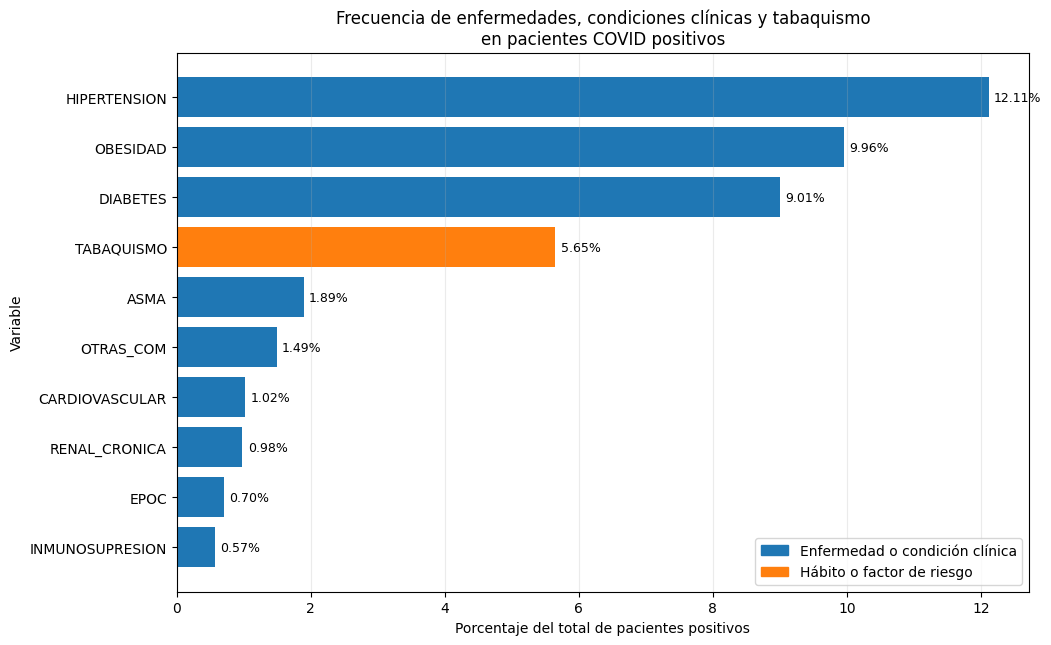

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/01_frecuencia_enfermedades_habito.png


In [ ]:
pdf = frecuencia_variables.to_pandas().sort_values("FRECUENCIA_PORCENTAJE")
colores_tipo = pdf["TIPO_VARIABLE"].map({
    "Enfermedad o condición clínica": "C0",
    "Hábito o factor de riesgo": "C1",
})

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(pdf["VARIABLE"], pdf["FRECUENCIA_PORCENTAJE"], color=colores_tipo)
ax.set_title("Frecuencia de enfermedades, condiciones clínicas y tabaquismo\nen pacientes COVID positivos")
ax.set_xlabel("Porcentaje del total de pacientes positivos")
ax.set_ylabel("Variable")
ax.grid(axis="x", alpha=0.25)
for i, valor in enumerate(pdf["FRECUENCIA_PORCENTAJE"]):
    ax.text(valor + 0.08, i, f"{valor:.2f}%", va="center", fontsize=9)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="C0", label="Enfermedad o condición clínica"),
    Patch(color="C1", label="Hábito o factor de riesgo"),
], loc="lower right")

guardar_figura(fig, "01_frecuencia_enfermedades_habito.png")

### 5.1 Gráfica circular de distribución de ocurrencias

Esta gráfica reproduce la idea del análisis inicial, pero con una etiqueta metodológicamente correcta: las porciones muestran la participación de cada variable en el total de **ocurrencias registradas como presentes**. No representan grupos exclusivos de pacientes, porque una misma persona puede contribuir a varias porciones.

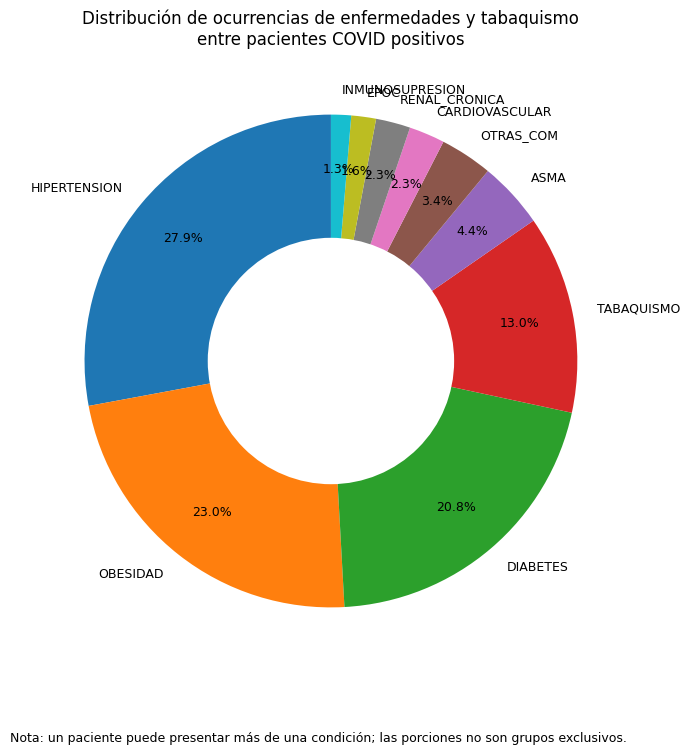

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/02_distribucion_ocurrencias_pastel.png


In [ ]:
pdf_pastel = frecuencia_variables.to_pandas().copy()
pdf_pastel = pdf_pastel[pdf_pastel["PACIENTES_CON_VARIABLE"] > 0]

fig, ax = plt.subplots(figsize=(10, 8))
ax.pie(
    pdf_pastel["PACIENTES_CON_VARIABLE"],
    labels=pdf_pastel["VARIABLE"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    textprops={"fontsize": 9},
)
centro = plt.Circle((0, 0), 0.50, fc="white")
ax.add_artist(centro)
ax.set_title(
    "Distribución de ocurrencias de enfermedades y tabaquismo\n"
    "entre pacientes COVID positivos"
)
fig.text(
    0.5, 0.02,
    "Nota: un paciente puede presentar más de una condición; las porciones no son grupos exclusivos.",
    ha="center", fontsize=9
)
guardar_figura(fig, "02_distribucion_ocurrencias_pastel.png")

## 6. Mortalidad por enfermedad y tabaquismo

La mortalidad “con la variable” se calcula entre pacientes con código `1`. La mortalidad “sin la variable” usa únicamente el código `2`; los códigos desconocidos no se incorporan a ninguno de esos dos grupos.

In [ ]:
expresiones_mortalidad = []
for variable in VARIABLES_ANALISIS:
    presente = pl.col(variable) == 1
    ausente = pl.col(variable) == 2
    expresiones_mortalidad.extend([
        presente.cast(pl.Int64).sum().alias(f"{variable}__CON"),
        (presente & pl.col("FALLECIDO")).cast(pl.Int64).sum().alias(f"{variable}__DEF_CON"),
        ausente.cast(pl.Int64).sum().alias(f"{variable}__SIN"),
        (ausente & pl.col("FALLECIDO")).cast(pl.Int64).sum().alias(f"{variable}__DEF_SIN"),
    ])

mortalidad_ancha = collect_streaming(
    lf_positivos.select(expresiones_mortalidad)
).row(0, named=True)

filas_mortalidad = []
for variable in VARIABLES_ANALISIS:
    con_var = int(mortalidad_ancha[f"{variable}__CON"] or 0)
    def_con = int(mortalidad_ancha[f"{variable}__DEF_CON"] or 0)
    sin_var = int(mortalidad_ancha[f"{variable}__SIN"] or 0)
    def_sin = int(mortalidad_ancha[f"{variable}__DEF_SIN"] or 0)
    mort_con = porcentaje(def_con, con_var)
    mort_sin = porcentaje(def_sin, sin_var)
    razon = np.nan if pd.isna(mort_sin) or mort_sin == 0 else mort_con / mort_sin
    filas_mortalidad.append({
        "TIPO_VARIABLE": "Enfermedad o condición clínica" if variable in ENFERMEDADES else "Hábito o factor de riesgo",
        "VARIABLE": variable,
        "PACIENTES_CON_VARIABLE": con_var,
        "FALLECIDOS_CON_VARIABLE": def_con,
        "NO_FALLECIDOS_CON_VARIABLE": con_var - def_con,
        "MORTALIDAD_CON_VARIABLE_PORCENTAJE": mort_con,
        "PACIENTES_CODIGO_2_SIN_VARIABLE": sin_var,
        "FALLECIDOS_SIN_VARIABLE": def_sin,
        "MORTALIDAD_SIN_VARIABLE_PORCENTAJE": mort_sin,
        "DIFERENCIA_PUNTOS_PORCENTUALES": mort_con - mort_sin,
        "RAZON_MORTALIDAD_DESCRIPTIVA": razon,
    })

mortalidad_variables = pl.DataFrame(filas_mortalidad).sort(
    "MORTALIDAD_CON_VARIABLE_PORCENTAJE", descending=True
)
guardar_csv(mortalidad_variables, "mortalidad_por_enfermedad_habito.csv")
display(mortalidad_variables.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/mortalidad_por_enfermedad_habito.csv


,TIPO_VARIABLE,VARIABLE,PACIENTES_CON_VARIABLE,FALLECIDOS_CON_VARIABLE,NO_FALLECIDOS_CON_VARIABLE,MORTALIDAD_CON_VARIABLE_PORCENTAJE,PACIENTES_CODIGO_2_SIN_VARIABLE,FALLECIDOS_SIN_VARIABLE,MORTALIDAD_SIN_VARIABLE_PORCENTAJE,DIFERENCIA_PUNTOS_PORCENTUALES,RAZON_MORTALIDAD_DESCRIPTIVA
0,Enfermedad o condición clínica,RENAL_CRONICA,64072,23247,40825,36.282620,6440859,301880,4.686952,31.595667,7.741196
1,Enfermedad o condición clínica,EPOC,45858,14232,31626,31.034934,6459000,310882,4.813160,26.221774,6.447933
2,Enfermedad o condición clínica,CARDIOVASCULAR,66337,16331,50006,24.618237,6438481,308744,4.795293,19.822945,5.133834
3,Enfermedad o condición clínica,DIABETES,587403,119934,467469,20.417669,5916559,205145,3.467303,16.950366,5.888632
4,Enfermedad o condición clínica,INMUNOSUPRESION,37240,7436,29804,19.967777,6467579,317695,4.912116,15.055660,4.065005
5,Enfermedad o condición clínica,HIPERTENSION,790052,144459,645593,18.284746,5714793,180701,3.161987,15.122759,5.782676
6,Enfermedad o condición clínica,OTRAS_COM,97419,16669,80750,17.110625,6375958,306983,4.814696,12.295929,3.553833
7,Enfermedad o condición clínica,OBESIDAD,649589,67498,582091,10.390878,5856384,257840,4.402717,5.988161,2.360106
8,Hábito o factor de riesgo,TABAQUISMO,368343,24163,344180,6.559918,6136122,300896,4.903683,1.656235,1.337753
9,Enfermedad o condición clínica,ASMA,123522,5591,117931,4.526319,6381510,319577,5.007859,-0.481539,0.903843


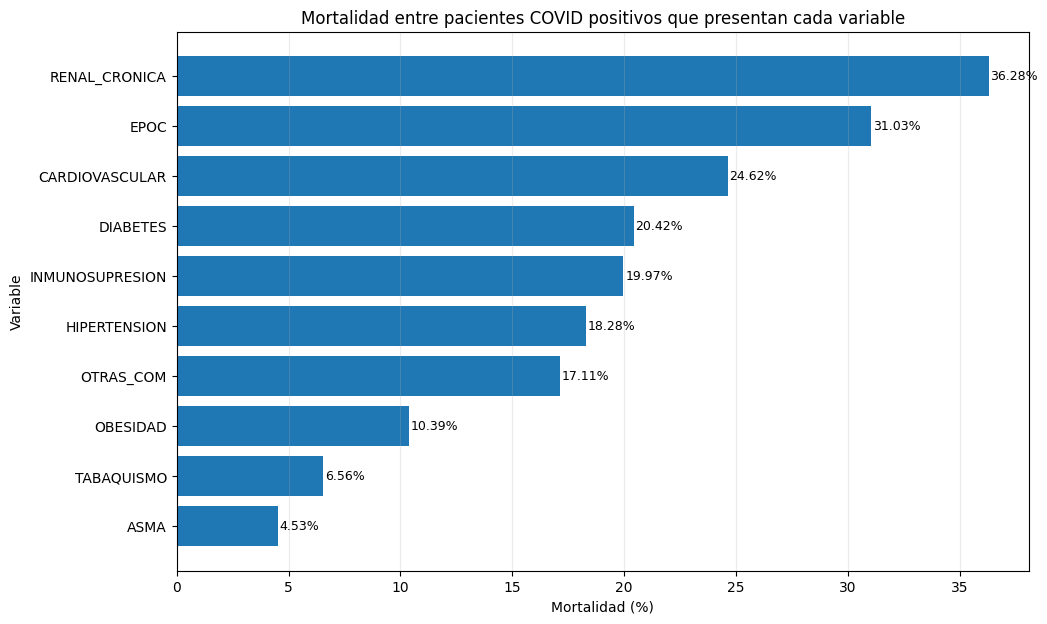

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/03_mortalidad_por_variable.png


In [ ]:
# Mortalidad entre quienes presentan cada variable
pdf = mortalidad_variables.to_pandas().sort_values("MORTALIDAD_CON_VARIABLE_PORCENTAJE")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(pdf["VARIABLE"], pdf["MORTALIDAD_CON_VARIABLE_PORCENTAJE"])
ax.set_title("Mortalidad entre pacientes COVID positivos que presentan cada variable")
ax.set_xlabel("Mortalidad (%)")
ax.set_ylabel("Variable")
ax.grid(axis="x", alpha=0.25)
for i, valor in enumerate(pdf["MORTALIDAD_CON_VARIABLE_PORCENTAJE"]):
    ax.text(valor + 0.08, i, f"{valor:.2f}%", va="center", fontsize=9)
guardar_figura(fig, "03_mortalidad_por_variable.png")

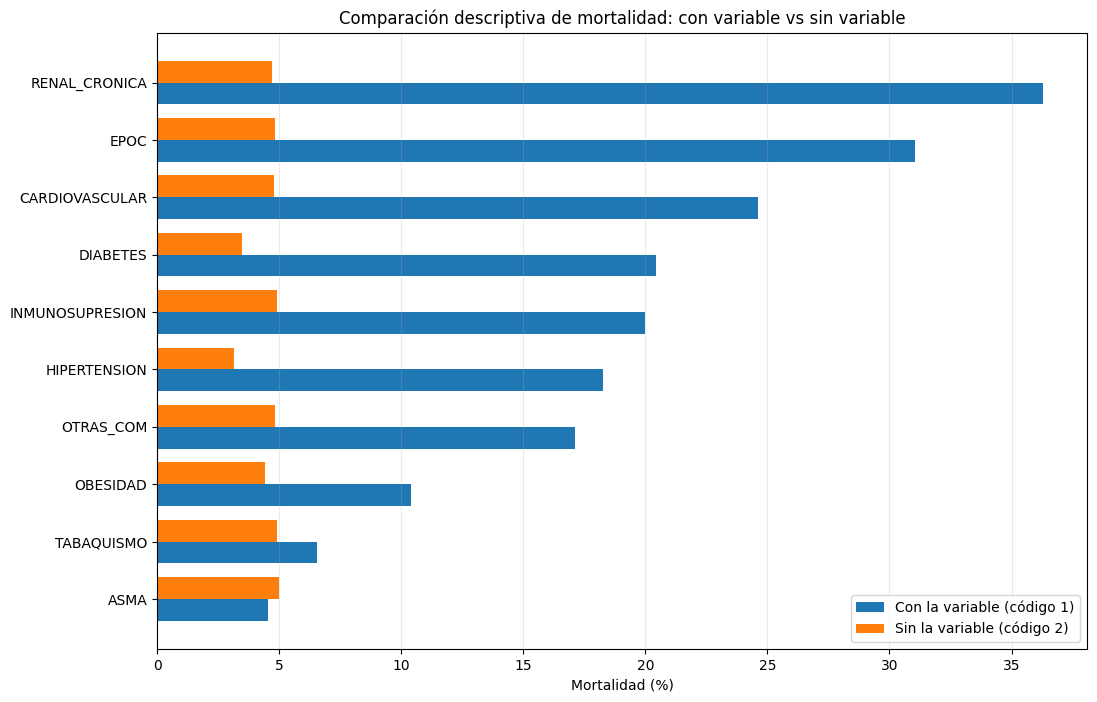

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/04_mortalidad_con_vs_sin_variable.png


In [ ]:
# Comparación: mortalidad con código 1 frente a mortalidad con código 2
pdf = mortalidad_variables.to_pandas().sort_values("MORTALIDAD_CON_VARIABLE_PORCENTAJE")
y = np.arange(len(pdf))
alto = 0.38

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(y - alto/2, pdf["MORTALIDAD_CON_VARIABLE_PORCENTAJE"], height=alto, label="Con la variable (código 1)")
ax.barh(y + alto/2, pdf["MORTALIDAD_SIN_VARIABLE_PORCENTAJE"], height=alto, label="Sin la variable (código 2)")
ax.set_yticks(y, pdf["VARIABLE"])
ax.set_xlabel("Mortalidad (%)")
ax.set_title("Comparación descriptiva de mortalidad: con variable vs sin variable")
ax.legend()
ax.grid(axis="x", alpha=0.25)
guardar_figura(fig, "04_mortalidad_con_vs_sin_variable.png")

### 6.1 Mortalidad segmentada al 100%

Cada barra representa exclusivamente a los pacientes positivos que presentan la variable. El segmento completo suma 100% y se divide entre fallecidos y no fallecidos.

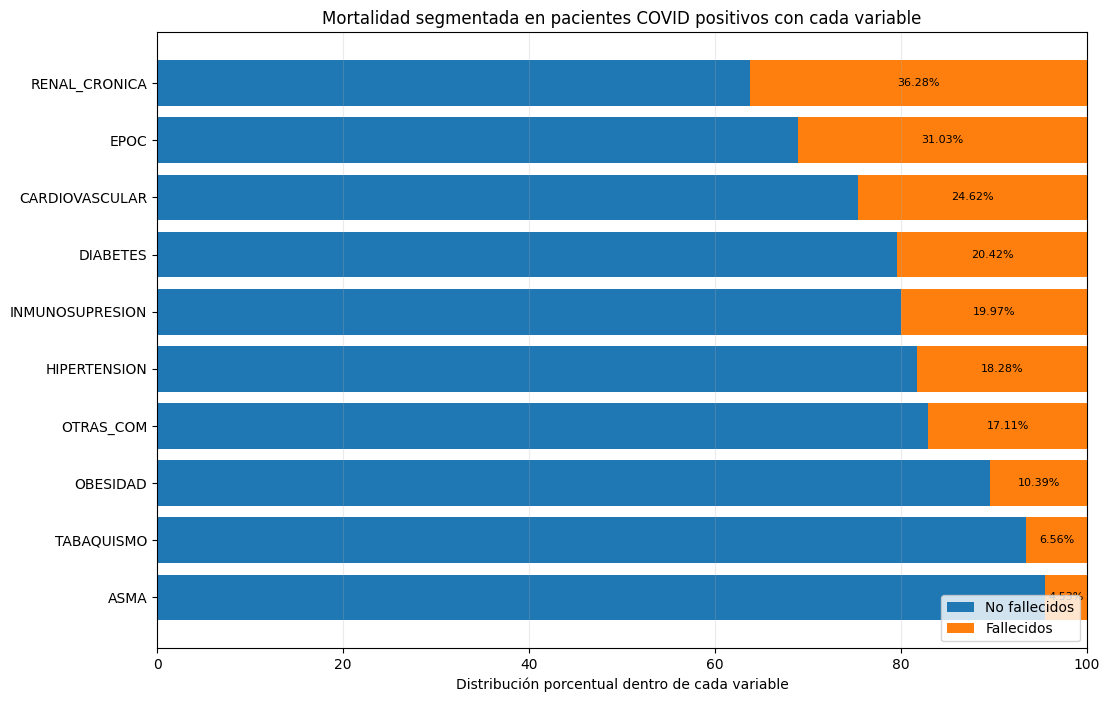

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/05_mortalidad_segmentada_100_por_variable.png


In [ ]:
pdf = mortalidad_variables.to_pandas().sort_values("MORTALIDAD_CON_VARIABLE_PORCENTAJE")
pdf["FALLECIDOS_PCT"] = pdf["MORTALIDAD_CON_VARIABLE_PORCENTAJE"]
pdf["NO_FALLECIDOS_PCT"] = 100 - pdf["FALLECIDOS_PCT"]

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(pdf["VARIABLE"], pdf["NO_FALLECIDOS_PCT"], label="No fallecidos")
ax.barh(
    pdf["VARIABLE"], pdf["FALLECIDOS_PCT"],
    left=pdf["NO_FALLECIDOS_PCT"], label="Fallecidos"
)
ax.set_xlim(0, 100)
ax.set_xlabel("Distribución porcentual dentro de cada variable")
ax.set_title("Mortalidad segmentada en pacientes COVID positivos con cada variable")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
for i, valor in enumerate(pdf["FALLECIDOS_PCT"]):
    ax.text(100 - valor/2, i, f"{valor:.2f}%", ha="center", va="center", fontsize=8)
guardar_figura(fig, "05_mortalidad_segmentada_100_por_variable.png")

## 7. Número de enfermedades registradas

`NUM_ENFERMEDADES` cuenta únicamente las nueve enfermedades con código `1`. Tabaquismo no se suma. La categoría “0” significa **cero enfermedades registradas como presentes**, no necesariamente ausencia confirmada cuando existen códigos desconocidos.

In [ ]:
distribucion_num_enfermedades = collect_streaming(
    lf_positivos.group_by("CATEGORIA_NUM_ENFERMEDADES")
    .agg([
        pl.len().alias("PACIENTES"),
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
    ])
).with_columns([
    (pl.col("PACIENTES") / total_positivos * 100).alias("PORCENTAJE_TOTAL_POSITIVOS"),
    (pl.col("DEFUNCIONES") / pl.col("PACIENTES") * 100).alias("MORTALIDAD_PORCENTAJE"),
])

pdf_num = ordenar_por_lista(
    distribucion_num_enfermedades.to_pandas(),
    "CATEGORIA_NUM_ENFERMEDADES",
    CATEGORIAS_NUM_ENFERMEDADES,
)
distribucion_num_enfermedades = pl.from_pandas(pdf_num)

guardar_csv(distribucion_num_enfermedades, "distribucion_numero_enfermedades.csv")
guardar_csv(
    distribucion_num_enfermedades.select([
        "CATEGORIA_NUM_ENFERMEDADES", "PACIENTES", "DEFUNCIONES", "MORTALIDAD_PORCENTAJE"
    ]),
    "mortalidad_numero_enfermedades.csv",
)
display(pdf_num)

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/distribucion_numero_enfermedades.csv
Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/mortalidad_numero_enfermedades.csv


,CATEGORIA_NUM_ENFERMEDADES,PACIENTES,DEFUNCIONES,PORCENTAJE_TOTAL_POSITIVOS,MORTALIDAD_PORCENTAJE
3,0,4856335,103699,74.449490,2.135335
2,1,1082388,95851,16.593426,8.855512
1,2,417400,77801,6.398903,18.639435
4,3,133442,37063,2.045717,27.774614
5,4,26473,9623,0.405841,36.350244
0,5 o más,6955,2728,0.106623,39.223580


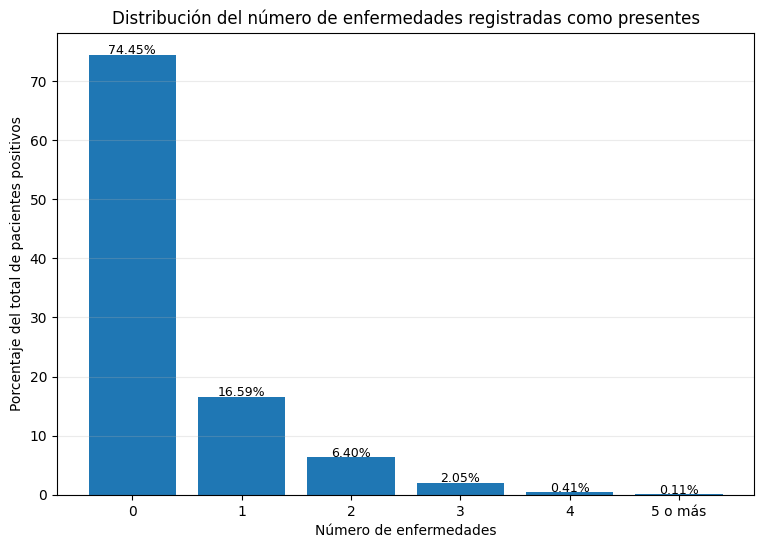

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/06_distribucion_numero_enfermedades.png


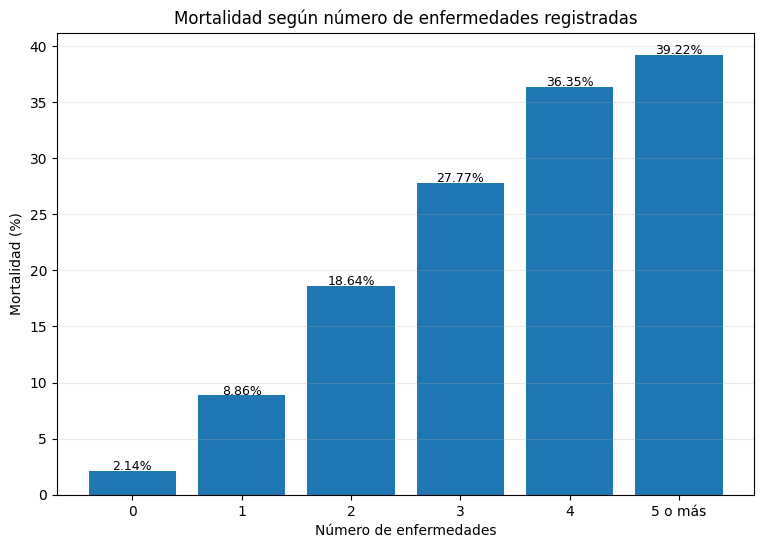

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/07_mortalidad_segun_numero_enfermedades.png


In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.bar(pdf_num["CATEGORIA_NUM_ENFERMEDADES"].astype(str), pdf_num["PORCENTAJE_TOTAL_POSITIVOS"])
ax.set_title("Distribución del número de enfermedades registradas como presentes")
ax.set_xlabel("Número de enfermedades")
ax.set_ylabel("Porcentaje del total de pacientes positivos")
ax.grid(axis="y", alpha=0.25)
for i, valor in enumerate(pdf_num["PORCENTAJE_TOTAL_POSITIVOS"]):
    ax.text(i, valor + 0.08, f"{valor:.2f}%", ha="center", fontsize=9)
guardar_figura(fig, "06_distribucion_numero_enfermedades.png")

fig, ax = plt.subplots(figsize=(9, 6))
ax.bar(pdf_num["CATEGORIA_NUM_ENFERMEDADES"].astype(str), pdf_num["MORTALIDAD_PORCENTAJE"])
ax.set_title("Mortalidad según número de enfermedades registradas")
ax.set_xlabel("Número de enfermedades")
ax.set_ylabel("Mortalidad (%)")
ax.grid(axis="y", alpha=0.25)
for i, valor in enumerate(pdf_num["MORTALIDAD_PORCENTAJE"]):
    ax.text(i, valor + 0.08, f"{valor:.2f}%", ha="center", fontsize=9)
guardar_figura(fig, "07_mortalidad_segun_numero_enfermedades.png")

## 8. Combinaciones de enfermedades

Se excluyen los pacientes con cero enfermedades registradas y no se incorpora tabaquismo en la combinación principal.

In [ ]:
componentes_combinacion = [
    pl.when(pl.col(variable) == 1)
    .then(pl.lit(variable))
    .otherwise(pl.lit(None, dtype=pl.String))
    for variable in ENFERMEDADES
]

lf_combinaciones = lf_positivos.with_columns(
    pl.concat_str(
        componentes_combinacion,
        separator=" + ",
        ignore_nulls=True,
    ).alias("COMBINACION_ENFERMEDADES")
)

combinaciones_enfermedades = collect_streaming(
    lf_combinaciones
    .filter(pl.col("NUM_ENFERMEDADES") > 0)
    .group_by(["COMBINACION_ENFERMEDADES", "NUM_ENFERMEDADES"])
    .agg([
        pl.len().alias("PACIENTES"),
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
    ])
    .with_columns([
        (pl.col("PACIENTES") / total_positivos * 100).alias("PORCENTAJE_UNIVERSO_POSITIVO"),
        (pl.col("DEFUNCIONES") / pl.col("PACIENTES") * 100).alias("MORTALIDAD_PORCENTAJE"),
    ])
    .sort("PACIENTES", descending=True)
    .head(TOP_COMBINACIONES)
)

guardar_csv(combinaciones_enfermedades, "combinaciones_enfermedades.csv")
display(combinaciones_enfermedades.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/combinaciones_enfermedades.csv


,COMBINACION_ENFERMEDADES,NUM_ENFERMEDADES,PACIENTES,DEFUNCIONES,PORCENTAJE_UNIVERSO_POSITIVO,MORTALIDAD_PORCENTAJE
0,OBESIDAD,1,379953,19555,5.824826,5.146689
1,HIPERTENSION,1,318004,36239,4.875124,11.395769
2,DIABETES,1,203534,26932,3.120255,13.232187
3,DIABETES + HIPERTENSION,2,182334,39542,2.795251,21.686575
4,HIPERTENSION + OBESIDAD,2,91958,11811,1.409752,12.843907
5,ASMA,1,77871,1160,1.193792,1.489643
6,DIABETES + HIPERTENSION + OBESIDAD,3,62189,14002,0.953381,22.515236
7,OTRAS_COM,1,50853,4433,0.779596,8.717283
8,DIABETES + OBESIDAD,2,41245,6165,0.632302,14.947266
9,DIABETES + HIPERTENSION + RENAL_CRONICA,3,16749,7829,0.256769,46.743089


In [ ]:
top_combos = combinaciones_enfermedades["COMBINACION_ENFERMEDADES"].to_list()

combinaciones_tabaquismo = collect_streaming(
    lf_combinaciones
    .filter(pl.col("COMBINACION_ENFERMEDADES").is_in(top_combos))
    .group_by(["COMBINACION_ENFERMEDADES", "TABAQUISMO_ESTADO"])
    .agg([
        pl.len().alias("PACIENTES"),
        pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
    ])
    .with_columns(
        (pl.col("DEFUNCIONES") / pl.col("PACIENTES") * 100)
        .alias("MORTALIDAD_PORCENTAJE")
    )
    .sort(["COMBINACION_ENFERMEDADES", "PACIENTES"], descending=[False, True])
)

guardar_csv(combinaciones_tabaquismo, "combinaciones_enfermedades_tabaquismo.csv")
display(combinaciones_tabaquismo.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/combinaciones_enfermedades_tabaquismo.csv


,COMBINACION_ENFERMEDADES,TABAQUISMO_ESTADO,PACIENTES,DEFUNCIONES,MORTALIDAD_PORCENTAJE
0,ASMA,Ausente,73362,1074,1.463973
1,ASMA,Presente,4484,83,1.851026
2,ASMA,Desconocido/no especificado,25,3,12.000000
3,ASMA + OBESIDAD,Ausente,11852,447,3.771515
4,ASMA + OBESIDAD,Presente,1296,44,3.395062
5,ASMA + OBESIDAD,Desconocido/no especificado,5,0,0.000000
6,CARDIOVASCULAR,Ausente,14270,1603,11.233357
7,CARDIOVASCULAR,Presente,1336,165,12.350299
8,CARDIOVASCULAR,Desconocido/no especificado,24,6,25.000000
9,DIABETES,Ausente,190689,25130,13.178526


## 9. Análisis por sexo

La frecuencia de cada variable se calcula dentro de cada categoría de sexo. La mortalidad se calcula entre quienes presentan la variable dentro de esa categoría.

In [ ]:
analisis_por_sexo = tabla_variables_por_grupo(lf_positivos, "SEXO_CATEGORIA").sort([
    "SEXO_CATEGORIA", "FRECUENCIA_PORCENTAJE"
], descending=[False, True])

guardar_csv(analisis_por_sexo, "analisis_por_sexo.csv")
display(analisis_por_sexo.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/analisis_por_sexo.csv


,SEXO_CATEGORIA,TIPO_VARIABLE,VARIABLE,TOTAL_GRUPO,PACIENTES_CON_VARIABLE,FRECUENCIA_PORCENTAJE,DEFUNCIONES_CON_VARIABLE,MORTALIDAD_PORCENTAJE
0,Hombre,Enfermedad o condición clínica,HIPERTENSION,3078006,368228,11.963200,80906,21.971713
1,Hombre,Enfermedad o condición clínica,OBESIDAD,3078006,293209,9.525940,36658,12.502345
2,Hombre,Enfermedad o condición clínica,DIABETES,3078006,280863,9.124836,68335,24.330367
3,Hombre,Hábito o factor de riesgo,TABAQUISMO,3078006,238405,7.745436,19630,8.233888
4,Hombre,Enfermedad o condición clínica,ASMA,3078006,44187,1.435572,2461,5.569511
5,Hombre,Enfermedad o condición clínica,OTRAS_COM,3078006,38440,1.248860,9120,23.725286
6,Hombre,Enfermedad o condición clínica,RENAL_CRONICA,3078006,35357,1.148698,13794,39.013491
7,Hombre,Enfermedad o condición clínica,CARDIOVASCULAR,3078006,35118,1.140933,10016,28.520986
8,Hombre,Enfermedad o condición clínica,EPOC,3078006,22497,0.730895,7811,34.720185
9,Hombre,Enfermedad o condición clínica,INMUNOSUPRESION,3078006,16355,0.531350,4041,24.708040


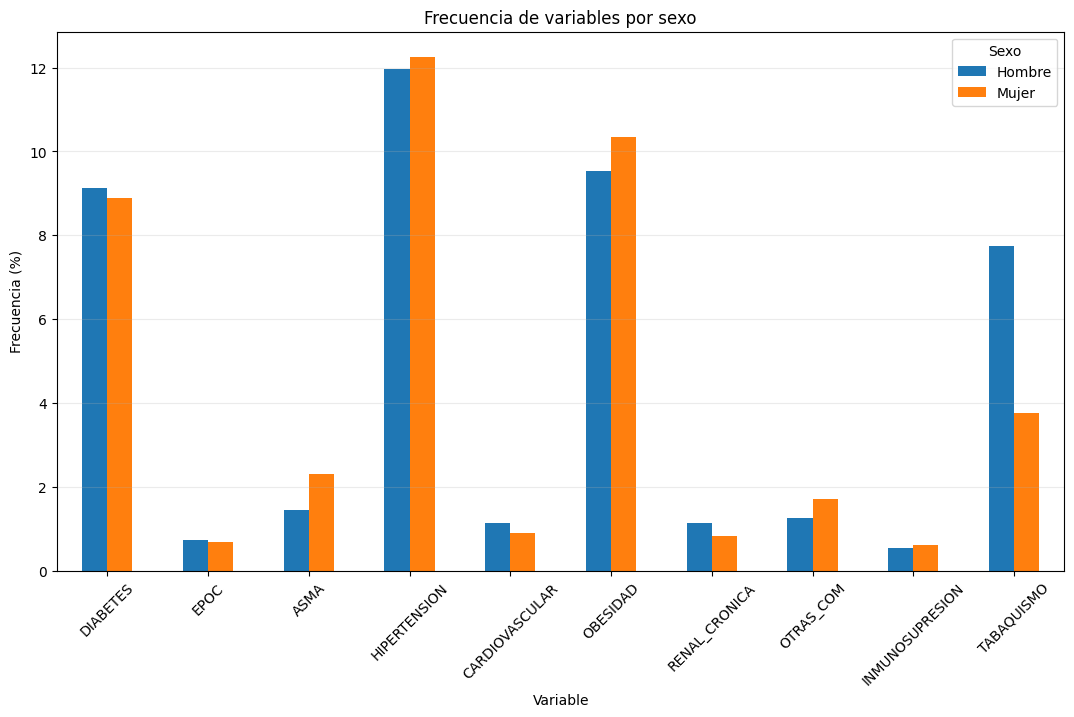

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/08_frecuencia_por_sexo.png


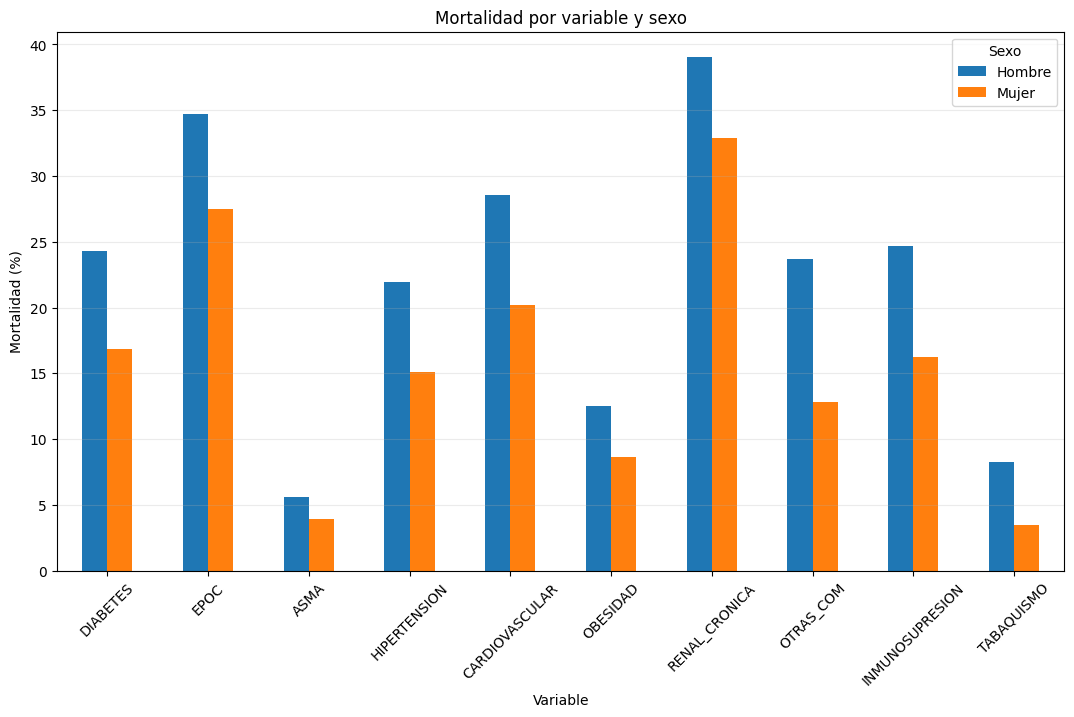

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/09_mortalidad_por_sexo.png


In [ ]:
pdf_sexo = analisis_por_sexo.to_pandas()
sexos_principales = [x for x in ["Mujer", "Hombre"] if x in pdf_sexo["SEXO_CATEGORIA"].unique()]

for metrica, titulo, archivo, eje_y in [
    ("FRECUENCIA_PORCENTAJE", "Frecuencia de variables por sexo", "08_frecuencia_por_sexo.png", "Frecuencia (%)"),
    ("MORTALIDAD_PORCENTAJE", "Mortalidad por variable y sexo", "09_mortalidad_por_sexo.png", "Mortalidad (%)"),
]:
    pivote = (
        pdf_sexo[pdf_sexo["SEXO_CATEGORIA"].isin(sexos_principales)]
        .pivot(index="VARIABLE", columns="SEXO_CATEGORIA", values=metrica)
        .reindex(VARIABLES_ANALISIS)
    )
    fig, ax = plt.subplots(figsize=(13, 7))
    pivote.plot(kind="bar", ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Variable")
    ax.set_ylabel(eje_y)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="Sexo")
    guardar_figura(fig, archivo)

## 10. Análisis por grupos de edad

Se generan tablas completas y mapas de calor. Los mapas permiten comparar patrones sin saturar la figura con decenas de barras.

In [ ]:
analisis_por_grupo_edad = tabla_variables_por_grupo(lf_positivos, "GRUPO_EDAD")

pdf_age_long = analisis_por_grupo_edad.to_pandas()
pdf_age_long = ordenar_por_lista(pdf_age_long, "GRUPO_EDAD", GRUPOS_EDAD_ORDEN)
analisis_por_grupo_edad = pl.from_pandas(pdf_age_long)

guardar_csv(analisis_por_grupo_edad, "analisis_por_grupo_edad.csv")
display(pdf_age_long.head(50))

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/analisis_por_grupo_edad.csv


,GRUPO_EDAD,TIPO_VARIABLE,VARIABLE,TOTAL_GRUPO,PACIENTES_CON_VARIABLE,FRECUENCIA_PORCENTAJE,DEFUNCIONES_CON_VARIABLE,MORTALIDAD_PORCENTAJE
89,0-17,Hábito o factor de riesgo,TABAQUISMO,423888,1508,0.355754,7,0.464191
87,0-17,Enfermedad o condición clínica,OTRAS_COM,423888,4748,1.120107,249,5.244313
86,0-17,Enfermedad o condición clínica,RENAL_CRONICA,423888,752,0.177405,55,7.313830
85,0-17,Enfermedad o condición clínica,OBESIDAD,423888,9828,2.318537,94,0.956451
84,0-17,Enfermedad o condición clínica,CARDIOVASCULAR,423888,1495,0.352688,91,6.086957
83,0-17,Enfermedad o condición clínica,HIPERTENSION,423888,1248,0.294417,57,4.567308
82,0-17,Enfermedad o condición clínica,ASMA,423888,10182,2.402050,18,0.176783
81,0-17,Enfermedad o condición clínica,EPOC,423888,290,0.068414,4,1.379310
80,0-17,Enfermedad o condición clínica,DIABETES,423888,1561,0.368258,60,3.843690
88,0-17,Enfermedad o condición clínica,INMUNOSUPRESION,423888,1952,0.460499,123,6.301230


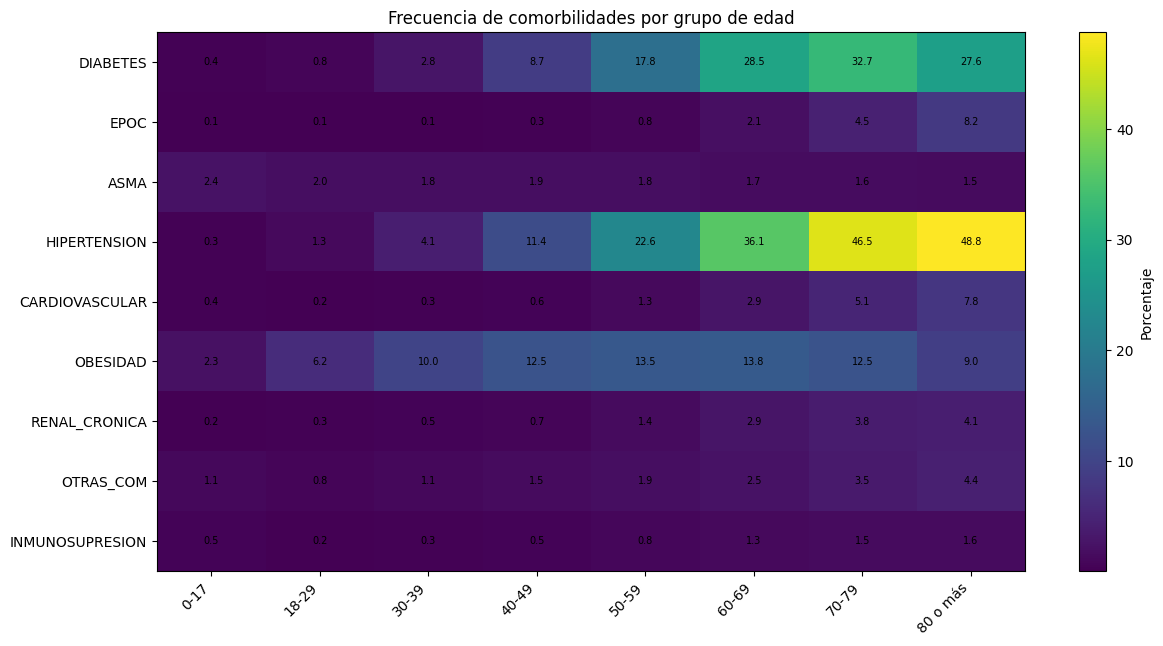

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/10_comorbilidades_por_rango_edad_frecuencia.png


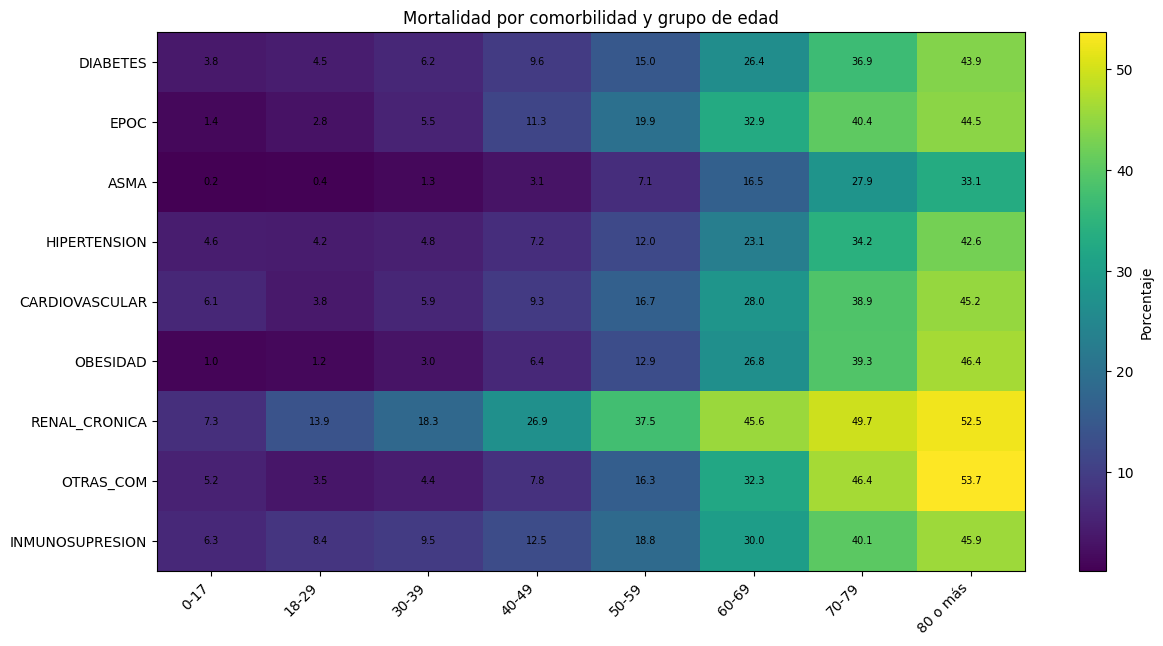

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/11_comorbilidades_por_rango_edad_mortalidad.png


In [ ]:
def mapa_calor_variables_edad(pdf_largo, metrica, titulo, archivo, variables):
    datos = (
        pdf_largo[pdf_largo["VARIABLE"].isin(variables)]
        .pivot(index="VARIABLE", columns="GRUPO_EDAD", values=metrica)
        .reindex(index=variables, columns=GRUPOS_EDAD_ORDEN[:8])
    )

    fig, ax = plt.subplots(figsize=(14, 7))
    imagen = ax.imshow(datos.to_numpy(dtype=float), aspect="auto")
    ax.set_xticks(np.arange(len(datos.columns)), datos.columns, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(datos.index)), datos.index)
    ax.set_title(titulo)
    barra = fig.colorbar(imagen, ax=ax)
    barra.set_label("Porcentaje")

    valores = datos.to_numpy(dtype=float)
    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):
            valor = valores[i, j]
            if not np.isnan(valor):
                ax.text(j, i, f"{valor:.1f}", ha="center", va="center", fontsize=7)

    guardar_figura(fig, archivo)

# Gráfica específica solicitada: comorbilidades frente a rangos de edad.
mapa_calor_variables_edad(
    pdf_age_long,
    "FRECUENCIA_PORCENTAJE",
    "Frecuencia de comorbilidades por grupo de edad",
    "10_comorbilidades_por_rango_edad_frecuencia.png",
    ENFERMEDADES,
)

mapa_calor_variables_edad(
    pdf_age_long,
    "MORTALIDAD_PORCENTAJE",
    "Mortalidad por comorbilidad y grupo de edad",
    "11_comorbilidades_por_rango_edad_mortalidad.png",
    ENFERMEDADES,
)

## 11. Mortalidad y frecuencia por entidad de residencia

La tabla de mortalidad usa `ENTIDAD_RES`. Los códigos no catalogados, no especificados o nulos se conservan por separado.

In [ ]:
# Frecuencia y mortalidad de cada variable por estado, sin expandir 6.5 millones de filas.
frecuencia_variables_por_estado = tabla_variables_por_grupo(
    lf_positivos, "ENTIDAD_RES_COD"
).with_columns(
    pl.col("ENTIDAD_RES_COD")
    .map_elements(nombre_entidad, return_dtype=pl.String)
    .alias("ENTIDAD_RES_NOMBRE")
).select([
    "ENTIDAD_RES_COD", "ENTIDAD_RES_NOMBRE", "TIPO_VARIABLE", "VARIABLE",
    "TOTAL_GRUPO", "PACIENTES_CON_VARIABLE", "FRECUENCIA_PORCENTAJE",
    "DEFUNCIONES_CON_VARIABLE", "MORTALIDAD_PORCENTAJE",
]).sort(["ENTIDAD_RES_COD", "FRECUENCIA_PORCENTAJE"], descending=[False, True])

guardar_csv(frecuencia_variables_por_estado, "frecuencia_variables_por_estado.csv")
display(frecuencia_variables_por_estado.to_pandas().head(50))

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/frecuencia_variables_por_estado.csv


,ENTIDAD_RES_COD,ENTIDAD_RES_NOMBRE,TIPO_VARIABLE,VARIABLE,TOTAL_GRUPO,PACIENTES_CON_VARIABLE,FRECUENCIA_PORCENTAJE,DEFUNCIONES_CON_VARIABLE,MORTALIDAD_PORCENTAJE
0,1,Aguascalientes,Enfermedad o condición clínica,HIPERTENSION,75942,9271,12.208001,1925,20.763672
1,1,Aguascalientes,Enfermedad o condición clínica,OBESIDAD,75942,6679,8.794870,526,7.875430
2,1,Aguascalientes,Enfermedad o condición clínica,DIABETES,75942,6192,8.153591,1445,23.336563
3,1,Aguascalientes,Hábito o factor de riesgo,TABAQUISMO,75942,4441,5.847884,395,8.894393
4,1,Aguascalientes,Enfermedad o condición clínica,OTRAS_COM,75942,2210,2.910116,391,17.692308
5,1,Aguascalientes,Enfermedad o condición clínica,ASMA,75942,1365,1.797424,55,4.029304
6,1,Aguascalientes,Enfermedad o condición clínica,RENAL_CRONICA,75942,1024,1.348397,372,36.328125
7,1,Aguascalientes,Enfermedad o condición clínica,CARDIOVASCULAR,75942,769,1.012615,200,26.007802
8,1,Aguascalientes,Enfermedad o condición clínica,EPOC,75942,592,0.779542,198,33.445946
9,1,Aguascalientes,Enfermedad o condición clínica,INMUNOSUPRESION,75942,388,0.510916,105,27.061856


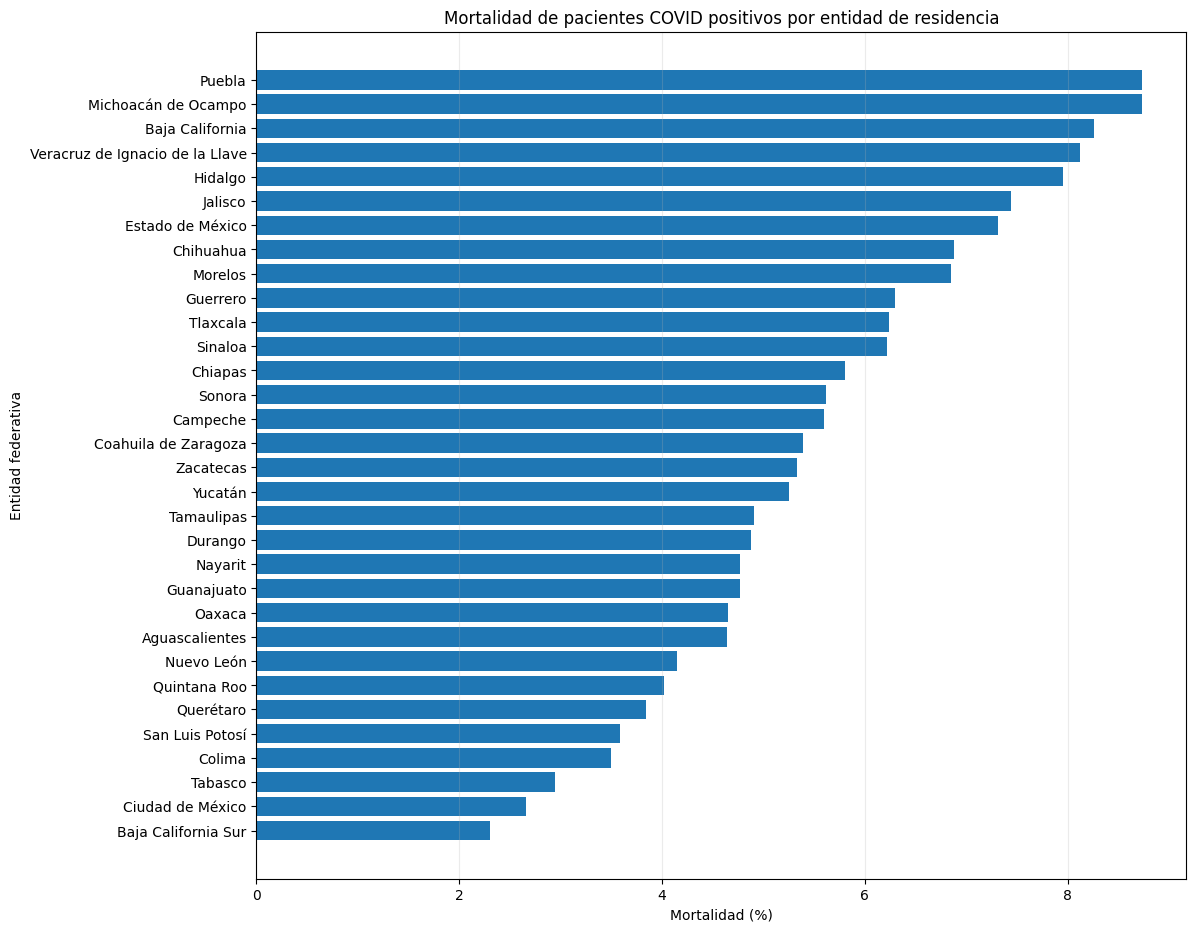

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/12_mortalidad_por_estado.png


In [ ]:
# Gráfica de mortalidad por entidad: se muestran las 32 entidades federativas.
pdf_estados = mortalidad_por_estado.to_pandas()
pdf_estados_32 = (
    pdf_estados[pdf_estados["ENTIDAD_RES_COD"].isin(range(1, 33))]
    .sort_values("MORTALIDAD_PORCENTAJE")
)

fig, ax = plt.subplots(figsize=(12, 11))
ax.barh(pdf_estados_32["ENTIDAD_RES_NOMBRE"], pdf_estados_32["MORTALIDAD_PORCENTAJE"])
ax.set_title("Mortalidad de pacientes COVID positivos por entidad de residencia")
ax.set_xlabel("Mortalidad (%)")
ax.set_ylabel("Entidad federativa")
ax.grid(axis="x", alpha=0.25)
guardar_figura(fig, "12_mortalidad_por_estado.png")

### 11.1 Comorbilidad predominante por estado

“Predominante” significa la enfermedad con mayor frecuencia registrada dentro de cada entidad. Tabaquismo se excluye porque se clasifica como hábito.

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/comorbilidad_predominante_por_estado.csv


,ENTIDAD_RES_COD,ENTIDAD_RES_NOMBRE,TIPO_VARIABLE,VARIABLE,TOTAL_GRUPO,PACIENTES_CON_VARIABLE,FRECUENCIA_PORCENTAJE,DEFUNCIONES_CON_VARIABLE,MORTALIDAD_PORCENTAJE
220,23,Quintana Roo,Enfermedad o condición clínica,HIPERTENSION,109478,9726,8.883977,1942,19.967098
80,9,Ciudad de México,Enfermedad o condición clínica,HIPERTENSION,1621261,157588,9.720088,17096,10.848542
280,29,Tlaxcala,Enfermedad o condición clínica,HIPERTENSION,49636,5008,10.089451,1099,21.944888
300,31,Yucatán,Enfermedad o condición clínica,HIPERTENSION,130564,14099,10.798536,3301,23.413008
190,20,Oaxaca,Enfermedad o condición clínica,OBESIDAD,134349,14510,10.800229,1283,8.842178
180,19,Nuevo León,Enfermedad o condición clínica,HIPERTENSION,364863,39654,10.868189,6308,15.907601
20,3,Baja California Sur,Enfermedad o condición clínica,OBESIDAD,117579,12933,10.999413,692,5.350653
140,15,Estado de México,Enfermedad o condición clínica,HIPERTENSION,649460,71663,11.034244,16540,23.080251
210,22,Querétaro,Enfermedad o condición clínica,HIPERTENSION,162120,17904,11.043671,2815,15.722744
90,10,Durango,Enfermedad o condición clínica,HIPERTENSION,74799,8856,11.839730,1671,18.868564


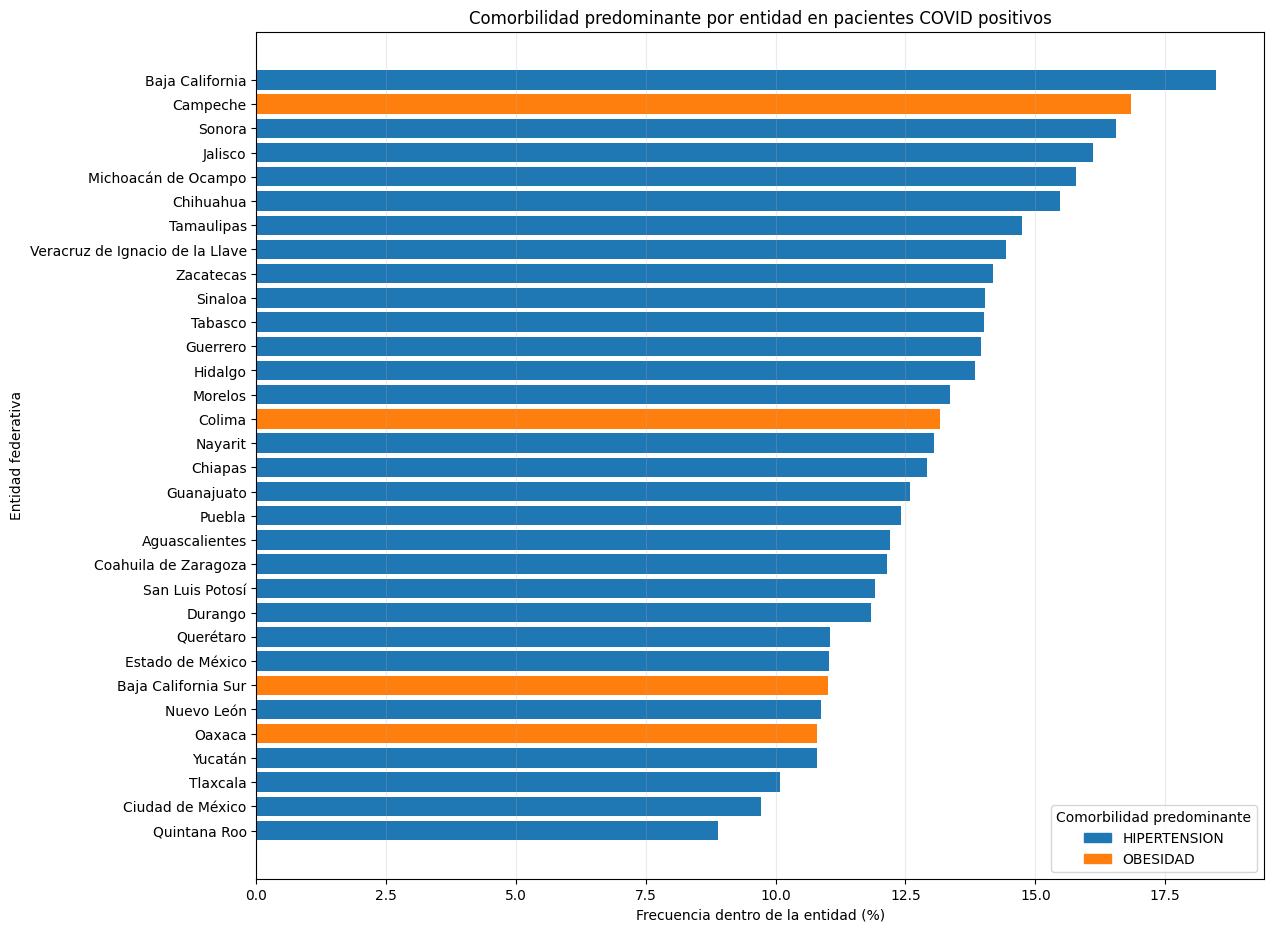

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/13_comorbilidad_predominante_por_estado.png


In [ ]:
pdf_estado_var = frecuencia_variables_por_estado.to_pandas()
predominante = (
    pdf_estado_var[
        (pdf_estado_var["TIPO_VARIABLE"] == "Enfermedad o condición clínica")
        & (pdf_estado_var["ENTIDAD_RES_COD"].isin(range(1, 33)))
    ]
    .sort_values(
        ["ENTIDAD_RES_COD", "FRECUENCIA_PORCENTAJE", "PACIENTES_CON_VARIABLE"],
        ascending=[True, False, False]
    )
    .groupby("ENTIDAD_RES_COD", as_index=False)
    .head(1)
    .sort_values("FRECUENCIA_PORCENTAJE")
)

comorbilidad_predominante_estado = pl.from_pandas(predominante)
guardar_csv(comorbilidad_predominante_estado, "comorbilidad_predominante_por_estado.csv")
display(predominante)

variables_predominantes = list(predominante["VARIABLE"].dropna().unique())
mapa_colores = {v: f"C{i % 10}" for i, v in enumerate(variables_predominantes)}

fig, ax = plt.subplots(figsize=(13, 11))
ax.barh(
    predominante["ENTIDAD_RES_NOMBRE"],
    predominante["FRECUENCIA_PORCENTAJE"],
    color=predominante["VARIABLE"].map(mapa_colores),
)
ax.set_title("Comorbilidad predominante por entidad en pacientes COVID positivos")
ax.set_xlabel("Frecuencia dentro de la entidad (%)")
ax.set_ylabel("Entidad federativa")
ax.grid(axis="x", alpha=0.25)

from matplotlib.patches import Patch
ax.legend(
    handles=[Patch(color=color, label=variable) for variable, color in mapa_colores.items()],
    title="Comorbilidad predominante",
    loc="lower right",
)
guardar_figura(fig, "13_comorbilidad_predominante_por_estado.png")

## 12. Comparación de Nuevo León, CDMX, Jalisco, Colima y Estado de México

Cada barra suma 100% y representa la composición de **ocurrencias de enfermedades presentes** dentro de la entidad. No representa prevalencias que deban sumar 100%, pues un paciente puede tener varias enfermedades. Tabaquismo se excluye de esta figura para conservar su clasificación como hábito.

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/composicion_comorbilidades_cinco_estados.csv


,ENTIDAD_RES_COD,ENTIDAD_RES_NOMBRE,TIPO_VARIABLE,VARIABLE,TOTAL_GRUPO,PACIENTES_CON_VARIABLE,FRECUENCIA_PORCENTAJE,DEFUNCIONES_CON_VARIABLE,MORTALIDAD_PORCENTAJE,TOTAL_OCURRENCIAS_ESTADO,COMPOSICION_OCURRENCIAS_PORCENTAJE
184,19,Nuevo León,Enfermedad o condición clínica,ASMA,364863,5793,1.587719,241,4.160193,123417,4.693843
186,19,Nuevo León,Enfermedad o condición clínica,CARDIOVASCULAR,364863,3145,0.861967,832,26.454690,123417,2.548271
181,19,Nuevo León,Enfermedad o condición clínica,DIABETES,364863,32574,8.927735,5480,16.823233,123417,26.393447
189,19,Nuevo León,Enfermedad o condición clínica,EPOC,364863,1255,0.343965,335,26.693227,123417,1.016878
180,19,Nuevo León,Enfermedad o condición clínica,HIPERTENSION,364863,39654,10.868189,6308,15.907601,123417,32.130096
188,19,Nuevo León,Enfermedad o condición clínica,INMUNOSUPRESION,364863,1484,0.406728,284,19.137466,123417,1.202428
182,19,Nuevo León,Enfermedad o condición clínica,OBESIDAD,364863,31191,8.548688,2946,9.445032,123417,25.272855
185,19,Nuevo León,Enfermedad o condición clínica,OTRAS_COM,364863,5620,1.540304,831,14.786477,123417,4.553668
187,19,Nuevo León,Enfermedad o condición clínica,RENAL_CRONICA,364863,2701,0.740278,1009,37.356535,123417,2.188515
84,9,Ciudad de México,Enfermedad o condición clínica,ASMA,1621261,30181,1.861576,564,1.868725,494861,6.098884


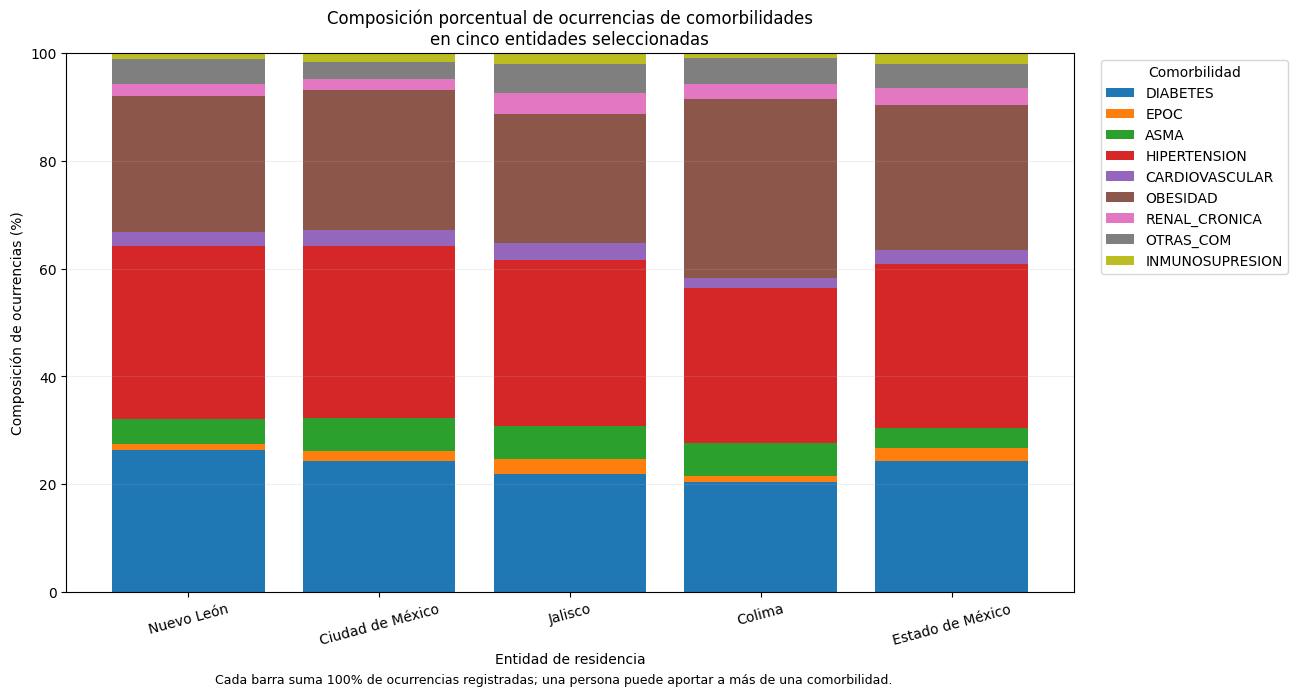

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/14_composicion_100_comorbilidades_cinco_estados.png


In [ ]:
pdf_cinco = pdf_estado_var[
    pdf_estado_var["ENTIDAD_RES_COD"].isin(ESTADOS_SELECCIONADOS.keys())
    & pdf_estado_var["VARIABLE"].isin(ENFERMEDADES)
].copy()

pdf_cinco["TOTAL_OCURRENCIAS_ESTADO"] = (
    pdf_cinco.groupby("ENTIDAD_RES_COD")["PACIENTES_CON_VARIABLE"].transform("sum")
)
pdf_cinco["COMPOSICION_OCURRENCIAS_PORCENTAJE"] = np.where(
    pdf_cinco["TOTAL_OCURRENCIAS_ESTADO"] > 0,
    pdf_cinco["PACIENTES_CON_VARIABLE"] / pdf_cinco["TOTAL_OCURRENCIAS_ESTADO"] * 100,
    np.nan,
)

orden_estados = list(ESTADOS_SELECCIONADOS.values())
pdf_cinco["ENTIDAD_RES_NOMBRE"] = pd.Categorical(
    pdf_cinco["ENTIDAD_RES_NOMBRE"], categories=orden_estados, ordered=True
)
pdf_cinco = pdf_cinco.sort_values(["ENTIDAD_RES_NOMBRE", "VARIABLE"])

composicion_cinco_estados = pl.from_pandas(pdf_cinco)
guardar_csv(composicion_cinco_estados, "composicion_comorbilidades_cinco_estados.csv")
display(pdf_cinco)

pivote = (
    pdf_cinco.pivot(
        index="ENTIDAD_RES_NOMBRE",
        columns="VARIABLE",
        values="COMPOSICION_OCURRENCIAS_PORCENTAJE",
    )
    .reindex(index=orden_estados, columns=ENFERMEDADES)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(13, 7))
fondo = np.zeros(len(pivote))
for variable in ENFERMEDADES:
    valores = pivote[variable].to_numpy()
    ax.bar(pivote.index.astype(str), valores, bottom=fondo, label=variable)
    fondo += valores

ax.set_ylim(0, 100)
ax.set_title(
    "Composición porcentual de ocurrencias de comorbilidades\n"
    "en cinco entidades seleccionadas"
)
ax.set_xlabel("Entidad de residencia")
ax.set_ylabel("Composición de ocurrencias (%)")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Comorbilidad", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.20)
fig.text(
    0.5, -0.02,
    "Cada barra suma 100% de ocurrencias registradas; una persona puede aportar a más de una comorbilidad.",
    ha="center", fontsize=9
)
guardar_figura(fig, "14_composicion_100_comorbilidades_cinco_estados.png")

## 13. Análisis específico del tabaquismo

El tabaquismo se mantiene como hábito o factor de riesgo. Las comparaciones son descriptivas y no controlan edad, sexo, severidad ni otras variables de confusión.

In [ ]:
def tabla_tabaquismo_dimension(lf, columnas_grupo, dimension):
    if isinstance(columnas_grupo, str):
        columnas_grupo = [columnas_grupo]
    tabla = collect_streaming(
        lf.group_by(columnas_grupo + ["TABAQUISMO_ESTADO"])
        .agg([
            pl.len().alias("PACIENTES"),
            pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
        ])
        .with_columns(
            (pl.col("DEFUNCIONES") / pl.col("PACIENTES") * 100)
            .alias("MORTALIDAD_PORCENTAJE")
        )
    )
    return tabla.with_columns(pl.lit(dimension).alias("DIMENSION"))

# Resumen general y estratificaciones principales.
tab_general = tabla_tabaquismo_dimension(
    lf_positivos.with_columns(pl.lit("Total").alias("CATEGORIA")),
    "CATEGORIA",
    "General",
)
tab_sexo = tabla_tabaquismo_dimension(lf_positivos, "SEXO_CATEGORIA", "Sexo").rename({
    "SEXO_CATEGORIA": "CATEGORIA"
})
tab_edad = tabla_tabaquismo_dimension(lf_positivos, "GRUPO_EDAD", "Grupo de edad").rename({
    "GRUPO_EDAD": "CATEGORIA"
})
tab_num = tabla_tabaquismo_dimension(
    lf_positivos, "CATEGORIA_NUM_ENFERMEDADES", "Número de enfermedades"
).rename({"CATEGORIA_NUM_ENFERMEDADES": "CATEGORIA"})

# Interacción con las cinco enfermedades más frecuentes.
top_5_enfermedades = (
    frecuencia_variables.filter(pl.col("VARIABLE").is_in(ENFERMEDADES))
    .sort("FRECUENCIA_PORCENTAJE", descending=True)
    .head(5)["VARIABLE"]
    .to_list()
)

filas_interaccion = []
for enfermedad in top_5_enfermedades:
    tab = collect_streaming(
        lf_positivos.filter(pl.col(enfermedad) == 1)
        .group_by("TABAQUISMO_ESTADO")
        .agg([
            pl.len().alias("PACIENTES"),
            pl.col("FALLECIDO").cast(pl.Int64).sum().alias("DEFUNCIONES"),
        ])
        .with_columns(
            (pl.col("DEFUNCIONES") / pl.col("PACIENTES") * 100)
            .alias("MORTALIDAD_PORCENTAJE")
        )
    )
    for fila in tab.iter_rows(named=True):
        filas_interaccion.append({
            "TABAQUISMO_ESTADO": fila["TABAQUISMO_ESTADO"],
            "PACIENTES": fila["PACIENTES"],
            "DEFUNCIONES": fila["DEFUNCIONES"],
            "MORTALIDAD_PORCENTAJE": fila["MORTALIDAD_PORCENTAJE"],
            "DIMENSION": "Enfermedad frecuente",
            "CATEGORIA": enfermedad,
        })

tab_interaccion = pl.DataFrame(filas_interaccion)

columnas_tabaco = [
    "DIMENSION", "CATEGORIA", "TABAQUISMO_ESTADO",
    "PACIENTES", "DEFUNCIONES", "MORTALIDAD_PORCENTAJE",
]
analisis_tabaquismo = pl.concat([
    tab_general.select(columnas_tabaco),
    tab_sexo.select(columnas_tabaco),
    tab_edad.select(columnas_tabaco),
    tab_num.select(columnas_tabaco),
    tab_interaccion.select(columnas_tabaco),
], how="vertical_relaxed")

guardar_csv(analisis_tabaquismo, "analisis_tabaquismo.csv")
display(analisis_tabaquismo.to_pandas())

Guardado: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/analisis_tabaquismo.csv


,DIMENSION,CATEGORIA,TABAQUISMO_ESTADO,PACIENTES,DEFUNCIONES,MORTALIDAD_PORCENTAJE
0,General,Total,Ausente,6136122,300896,4.903683
1,General,Total,Desconocido/no especificado,18528,1706,9.207686
2,General,Total,Presente,368343,24163,6.559918
3,Sexo,Mujer,Ausente,3306435,120524,3.645134
4,Sexo,Mujer,Presente,129938,4533,3.488587
5,Sexo,Hombre,Ausente,2829687,180372,6.374274
6,Sexo,Mujer,Desconocido/no especificado,8614,566,6.570699
7,Sexo,Hombre,Presente,238405,19630,8.233888
8,Sexo,Hombre,Desconocido/no especificado,9914,1140,11.498890
9,Grupo de edad,50-59,Ausente,881376,60222,6.832725


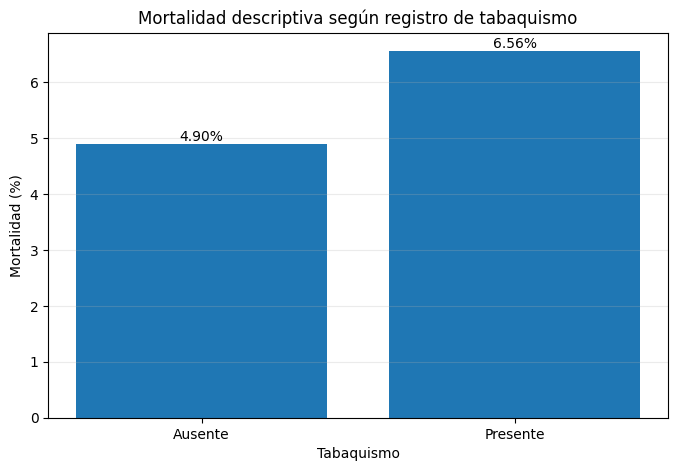

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/15_mortalidad_tabaquismo_general.png


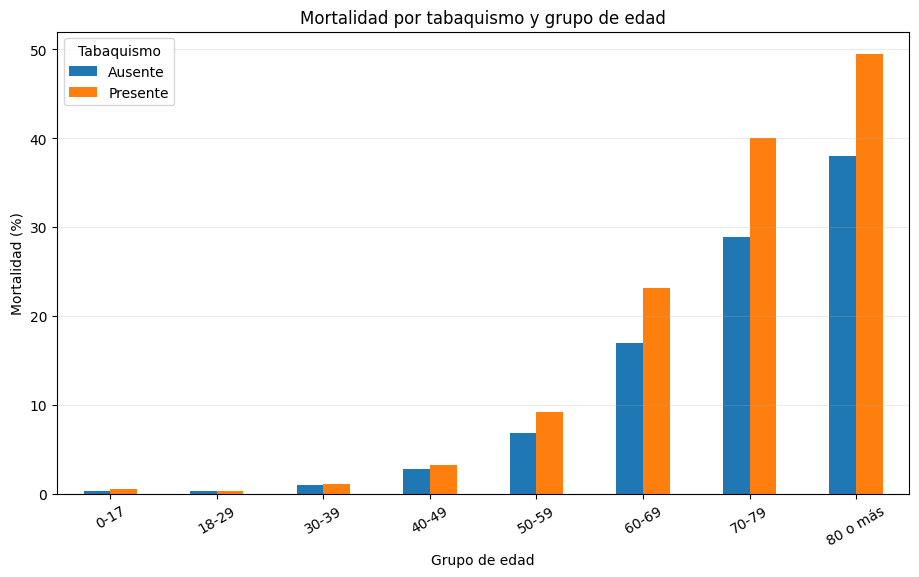

Guardada: /content/drive/MyDrive/Big Data/resultados/Analisis_Comorbilidades/graficas/16_mortalidad_tabaquismo_por_edad.png


In [ ]:
pdf_tabaco = analisis_tabaquismo.to_pandas()

general_tabaco = pdf_tabaco[
    (pdf_tabaco["DIMENSION"] == "General")
    & (pdf_tabaco["TABAQUISMO_ESTADO"].isin(["Presente", "Ausente"]))
]
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(general_tabaco["TABAQUISMO_ESTADO"], general_tabaco["MORTALIDAD_PORCENTAJE"])
ax.set_title("Mortalidad descriptiva según registro de tabaquismo")
ax.set_xlabel("Tabaquismo")
ax.set_ylabel("Mortalidad (%)")
ax.grid(axis="y", alpha=0.25)
for i, valor in enumerate(general_tabaco["MORTALIDAD_PORCENTAJE"]):
    ax.text(i, valor + 0.05, f"{valor:.2f}%", ha="center")
guardar_figura(fig, "15_mortalidad_tabaquismo_general.png")

edad_tabaco = pdf_tabaco[
    (pdf_tabaco["DIMENSION"] == "Grupo de edad")
    & (pdf_tabaco["TABAQUISMO_ESTADO"].isin(["Presente", "Ausente"]))
].copy()
edad_tabaco = ordenar_por_lista(edad_tabaco, "CATEGORIA", GRUPOS_EDAD_ORDEN)
pivote_tabaco_edad = edad_tabaco.pivot(
    index="CATEGORIA", columns="TABAQUISMO_ESTADO", values="MORTALIDAD_PORCENTAJE"
).reindex(GRUPOS_EDAD_ORDEN[:8])

fig, ax = plt.subplots(figsize=(11, 6))
pivote_tabaco_edad.plot(kind="bar", ax=ax)
ax.set_title("Mortalidad por tabaquismo y grupo de edad")
ax.set_xlabel("Grupo de edad")
ax.set_ylabel("Mortalidad (%)")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Tabaquismo")
guardar_figura(fig, "16_mortalidad_tabaquismo_por_edad.png")

## 14. Resumen automático de hallazgos

El texto generado utiliza lenguaje descriptivo. Debe revisarse antes de incorporarse al informe, especialmente cuando una categoría tiene pocos pacientes o muchos valores desconocidos.

In [ ]:
# Selección de hallazgos principales.
top_frecuencia = frecuencia_variables.sort("FRECUENCIA_PORCENTAJE", descending=True).row(0, named=True)
top_mortalidad = mortalidad_variables.sort("MORTALIDAD_CON_VARIABLE_PORCENTAJE", descending=True).row(0, named=True)

top_estado = (
    mortalidad_por_estado
    .filter(pl.col("ENTIDAD_RES_COD").is_in(list(range(1, 33))))
    .sort("MORTALIDAD_PORCENTAJE", descending=True)
    .row(0, named=True)
)

fila_cero = distribucion_num_enfermedades.filter(
    pl.col("CATEGORIA_NUM_ENFERMEDADES") == "0"
).row(0, named=True)
fila_cinco = distribucion_num_enfermedades.filter(
    pl.col("CATEGORIA_NUM_ENFERMEDADES") == "5 o más"
).row(0, named=True)

lineas = [
    "RESUMEN AUTOMÁTICO DE RESULTADOS",
    "================================",
    "",
    f"Registros limpios analizados: {total_registros:,}.",
    f"Pacientes COVID positivos: {total_positivos:,}.",
    f"Defunciones entre positivos: {total_fallecidos:,}.",
    f"Mortalidad general observada: {porcentaje(total_fallecidos, total_positivos):.2f}%.",
    "",
    (
        f"La variable con mayor frecuencia fue {top_frecuencia['VARIABLE']}, "
        f"registrada en {int(top_frecuencia['PACIENTES_CON_VARIABLE']):,} pacientes "
        f"({top_frecuencia['FRECUENCIA_PORCENTAJE']:.2f}% del universo positivo)."
    ),
    (
        f"La mayor mortalidad descriptiva entre quienes presentaron una variable se observó en "
        f"{top_mortalidad['VARIABLE']}: {top_mortalidad['MORTALIDAD_CON_VARIABLE_PORCENTAJE']:.2f}%."
    ),
    (
        f"Entre las 32 entidades federativas, la mayor mortalidad observada correspondió a "
        f"{top_estado['ENTIDAD_RES_NOMBRE']} ({top_estado['MORTALIDAD_PORCENTAJE']:.2f}%)."
    ),
    (
        f"La mortalidad en pacientes con cero enfermedades registradas como presentes fue "
        f"{fila_cero['MORTALIDAD_PORCENTAJE']:.2f}%, mientras que en la categoría de cinco o más "
        f"fue {fila_cinco['MORTALIDAD_PORCENTAJE']:.2f}%."
    ),
    "",
    "ADVERTENCIAS DE INTERPRETACIÓN",
    "- Los resultados describen asociaciones y no demuestran causalidad.",
    "- Una variable frecuente puede concentrar muchas defunciones sin tener la mortalidad porcentual más alta.",
    "- Una mortalidad alta basada en pocos pacientes debe interpretarse con precaución.",
    "- Los códigos 97, 98, 99, otros códigos y nulos no se consideraron presencia ni ausencia.",
    "- El conteo de cero enfermedades significa cero códigos 1, no ausencia clínica confirmada.",
    "- La gráfica circular y la comparación de cinco estados usan ocurrencias de condiciones; un paciente puede aportar varias.",
    "- El análisis se limita a las variables y registros disponibles en el dataset abierto de COVID-19.",
]

ruta_resumen = DIR_RESULTADOS / "resumen_resultados.txt"
ruta_resumen.write_text("\n".join(lineas), encoding="utf-8")
print("\n".join(lineas))
print("\nGuardado:", ruta_resumen)

RESUMEN AUTOMÁTICO DE RESULTADOS

Registros limpios analizados: 17,311,019.
Pacientes COVID positivos: 6,522,993.
Defunciones entre positivos: 326,765.
Mortalidad general observada: 5.01%.

La variable con mayor frecuencia fue HIPERTENSION, registrada en 790,052 pacientes (12.11% del universo positivo).
La mayor mortalidad descriptiva entre quienes presentaron una variable se observó en RENAL_CRONICA: 36.28%.
Entre las 32 entidades federativas, la mayor mortalidad observada correspondió a Puebla (8.74%).
La mortalidad en pacientes con cero enfermedades registradas como presentes fue 2.14%, mientras que en la categoría de cinco o más fue 39.22%.

ADVERTENCIAS DE INTERPRETACIÓN
- Los resultados describen asociaciones y no demuestran causalidad.
- Una variable frecuente puede concentrar muchas defunciones sin tener la mortalidad porcentual más alta.
- Una mortalidad alta basada en pocos pacientes debe interpretarse con precaución.
- Los códigos 97, 98, 99, otros códigos y nulos no se cons

## 15. Inventario de archivos generados

La celda siguiente verifica qué CSV, TXT y PNG se guardaron en Google Drive.

In [ ]:
archivos_generados = sorted([
    p.relative_to(DIR_RESULTADOS).as_posix()
    for p in DIR_RESULTADOS.rglob("*")
    if p.is_file()
])

inventario = pl.DataFrame({"ARCHIVO_GENERADO": archivos_generados})
display(inventario.to_pandas())
print(f"Total de archivos generados: {len(archivos_generados)}")

# Liberación final de referencias pequeñas; el Parquet nunca se duplicó ni modificó.
gc.collect()

,ARCHIVO_GENERADO
0,analisis_por_grupo_edad.csv
1,analisis_por_sexo.csv
2,analisis_tabaquismo.csv
3,calidad_variables.csv
4,combinaciones_enfermedades.csv
5,combinaciones_enfermedades_tabaquismo.csv
6,comorbilidad_predominante_por_estado.csv
7,composicion_comorbilidades_cinco_estados.csv
8,distribucion_grupo_edad.csv
9,distribucion_numero_enfermedades.csv


Total de archivos generados: 34


46434

## Guía para redactar las interpretaciones del short paper

Al interpretar cada resultado, diferencia tres conceptos:

1. **Frecuencia:** proporción de pacientes positivos que presentan una condición.
2. **Número absoluto de defunciones:** cantidad de muertes observadas en ese grupo.
3. **Mortalidad:** proporción de fallecidos dentro del grupo que presenta la condición.

Una enfermedad puede concentrar muchas defunciones porque es frecuente, aunque su mortalidad porcentual no sea la más alta. En sentido contrario, una condición poco frecuente puede mostrar una mortalidad elevada basada en pocos pacientes. Evita frases causales y considera edad, sexo, severidad y otras variables como posibles factores de confusión no controlados.